<a href="https://colab.research.google.com/github/Miguithub/fourier/blob/main/Fourier_10seg_2325.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BTC: EDA y selección de ventanas representativas a 10 segundos
**Estado: notebook preparado, sin ejecutar. No contiene resultados ni un n óptimo calculado.**

Fuente: [carpeta de Drive](https://drive.google.com/drive/u/0/folders/1zeZ1I1yrJd2fBcoZw2e67YeJeQ2ctf4D). Archivo confirmado **solo por listado**: `BTC_1s_2023_2025.parquet`. No se inspeccionaron filas ni esquema al preparar este notebook.

Secciones independientes: **close → close_ln → diff_close_ln → r2**. DuckDB limita memoria y derrama a disco; PyArrow lee el esquema únicamente cuando ejecutes la preparación. No se carga el parquet de 1 segundo en pandas.

## Preguntas y límites
1. ¿Cuál es el menor n que satisface una similitud distributiva prefijada?
2. ¿Qué n equilibra tamaño, estabilidad histórica, colas, dependencia y predicción?
3. ¿Existe una ventana común para las cuatro variables?

Una ventana contigua conserva el orden temporal; una muestra aleatoria no responde la misma pregunta. N es la población empírica observada, no una distribución universal de BTC. Precios no estacionarios pueden hacer imposible representar N con una ventana reciente corta. No se forzará una respuesta.

**Convenciones:** logaritmo natural; retornos sin multiplicar por 100; `r2 = Σ (Δ ln close_1s)²` dentro de cada bloque de 10 segundos. Es variación realizada, sin centrar ni dividir por 10, y no es R² ni el cuadrado del retorno agregado. El índice del bloque corresponde a su último segundo (inicio + 9 s); no usa precios futuros. `diff_close_ln` es la diferencia entre cierres consecutivos a 10 s. Solo se aceptan bloques con 10 observaciones y 10 retornos de 1 s válidos. Los huecos quedan como NaN, nunca se rellenan.

**Similitud porcentual operacional:** 100 × (1 − distancia Jensen–Shannon en base 2). No es probabilidad ni confianza. KL se reporta aparte, con soporte común y suavizado explícito. Los umbrales son 70%, 80%, 90%, 95% y 99%; pueden no alcanzarse. También se controlan Wasserstein/IQR, colas, dispersión y ACF.

**Advertencias de interpretación:** aumentar n no elimina autocorrelación ni ARCH. ADF/KPSS no certifican representatividad. AIC/BIC seleccionan orden sobre la misma muestra, no ventanas de distinto tamaño. Los tests sobre niveles y con millones de puntos requieren cautela: se informan tamaños de efecto, ventanas acotadas, corrección BH y supuestos. Ningún porcentaje garantiza parecido “en todo”.

In [ ]:
# Ejecutar manualmente SOLO cuando quieras comenzar. Esta celda no instala nada.
# En Colab, antes de los imports: %pip install duckdb pyarrow numpy pandas scipy statsmodels matplotlib
from pathlib import Path
import os, gc, json, warnings, platform, importlib.metadata
import numpy as np
import pandas as pd
import duckdb, pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import jensenshannon
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_white, het_arch
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from IPython.display import display

# Acceso robusto: ruta montada, ruta explícita o Drive autenticado por ID.
# La descarga alternativa SOLO ocurre cuando ejecutes esta celda.
import shutil, hashlib
SOURCE_FILE_ID = '1wTNpf89uUomVz29wvzAebnc7kPgGYA-K'
SOURCE_NAME = 'BTC_1s_2023_2025.parquet'
DRIVE_BASE = Path('/content/drive/MyDrive/Neural/BTC/LSTM+')
LOCAL_CACHE = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'btc_eda_source_cache'
SOURCE_OVERRIDE = os.environ.get('BTC_PARQUET_PATH', '').strip()

def source_from_drive_id():
    try:
        from google.colab import auth
        auth.authenticate_user()
        import google.auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaIoBaseDownload
        from googleapiclient.errors import HttpError
    except ImportError as exc:
        raise RuntimeError(
            'Fuera de Colab: definir BTC_PARQUET_PATH con la ruta local completa. '
            'En Colab: instalar google-api-python-client google-auth si faltan.'
        ) from exc
    credentials, _ = google.auth.default()
    service = build('drive', 'v3', credentials=credentials, cache_discovery=False)
    try:
        meta = service.files().get(
            fileId=SOURCE_FILE_ID, supportsAllDrives=True,
            fields='id,name,size,md5Checksum,modifiedTime,capabilities(canDownload)'
        ).execute()
    except HttpError as exc:
        raise RuntimeError(
            'La cuenta autenticada no pudo acceder al ID exacto del parquet. '
            'Abrir https://drive.google.com/file/d/' + SOURCE_FILE_ID +
            '/view con esa cuenta y comprobar acceso; autenticarse con la cuenta correcta. '
            'No se buscó otro archivo por nombre.'
        ) from exc
    if meta['name'] != SOURCE_NAME or 'size' not in meta:
        raise ValueError('El ID no corresponde al parquet esperado: ' + str(meta))
    if meta.get('capabilities', {}).get('canDownload') is False:
        raise PermissionError('Esta cuenta puede ver el archivo pero no descargarlo.')
    expected_size = int(meta['size'])
    LOCAL_CACHE.mkdir(parents=True, exist_ok=True)
    destination = LOCAL_CACHE / (SOURCE_FILE_ID + '_' + SOURCE_NAME)
    stamp = destination.with_suffix('.verified.json')
    signature = {key: meta.get(key) for key in ['id','size','md5Checksum','modifiedTime']}
    if destination.is_file() and destination.stat().st_size == expected_size and stamp.is_file():
        if json.loads(stamp.read_text()) == signature:
            print('Se reutiliza la copia local previamente verificada.')
            return destination
    part = destination.with_suffix('.part')
    free = shutil.disk_usage(LOCAL_CACHE).free
    if free < expected_size + 2 * 1024**3:
        raise OSError(
            f'Espacio libre insuficiente: {free/1024**3:.1f} GiB; '
            f'archivo: {expected_size/1024**3:.1f} GiB + margen de 2 GiB. '
            'El análisis y el spill necesitarán espacio adicional.'
        )
    print(f'Ruta montada no disponible. Copiando el ID exacto a disco '
          f'({expected_size/1024**3:.2f} GiB), en bloques de 8 MiB.')
    request = service.files().get_media(fileId=SOURCE_FILE_ID, supportsAllDrives=True)
    with part.open('wb') as handle:
        downloader = MediaIoBaseDownload(handle, request, chunksize=8*1024**2)
        done, previous = False, -1
        while not done:
            progress, done = downloader.next_chunk(num_retries=3)
            percent = int(progress.progress()*100) if progress else 0
            if percent//10 > previous or done:
                print(f'Copiado: {percent}%')
                previous = percent//10
    if part.stat().st_size != expected_size:
        raise IOError('Copia incompleta; no se usará para el análisis. Reejecutar esta celda.')
    if meta.get('md5Checksum'):
        digest = hashlib.md5()
        with part.open('rb') as handle:
            for chunk in iter(lambda: handle.read(8*1024**2), b''):
                digest.update(chunk)
        if digest.hexdigest() != meta['md5Checksum']:
            raise IOError('Checksum incorrecto; no se usará la copia. Reejecutar esta celda.')
    part.replace(destination)
    stamp.write_text(json.dumps(signature))
    return destination

if SOURCE_OVERRIDE:
    SOURCE = Path(SOURCE_OVERRIDE).expanduser()
    if not SOURCE.is_file():
        raise FileNotFoundError(f'BTC_PARQUET_PATH no existe: {SOURCE}')
else:
    try:
        from google.colab import drive as colab_drive
    except ImportError:
        colab_drive = None
    if colab_drive is not None and not Path('/content/drive/MyDrive').is_dir():
        try:
            colab_drive.mount('/content/drive')
        except Exception as exc:
            print('No se pudo montar Drive; se intentará acceso autenticado por ID:', type(exc).__name__)
    mounted_source = DRIVE_BASE / SOURCE_NAME
    local_source = Path.cwd() / SOURCE_NAME
    SOURCE = mounted_source if mounted_source.is_file() else (
        local_source if local_source.is_file() else source_from_drive_id()
    )
BASE = SOURCE.parent
# Si la carpeta original es visible, se conservan allí los resultados.
# Si no lo es, OUT queda local: copiar resultados antes de cerrar el runtime.
OUT = (DRIVE_BASE if DRIVE_BASE.is_dir() else BASE) / 'EDA_close_10s_resultados'
print('Fuente localizada:', SOURCE)
print('Resultados:', OUT)
if not str(OUT).startswith('/content/drive/'):
    print('ATENCIÓN: los resultados se guardarán en disco local; no se suben automáticamente a Drive.')

# Spill en disco local: evitar archivos temporales masivos en Drive.
WORK = Path('/content/btc_eda_work') if Path('/content').exists() else Path.cwd() / 'btc_eda_work'
TIMESTAMP_COLUMN = None  # si no se detecta un único candidato, indicar aquí su nombre
TIMESTAMP_UNIT = None    # obligatorio para época numérica: 's', 'ms', 'us' o 'ns'
SOURCE_TIMEZONE = 'UTC'  # para fechas sin zona; cambiar si corresponde
MEMORY_LIMIT = '1GB'
THREADS = 2
GRID_N = [60, 120, 360, 2160, 8640, 60480, 259200, 777600]  # 10 min ... 90 días
THRESHOLDS = [.70, .80, .90, .95, .99]
TARGET = .95
N_HIST = 24
TEST_N = 5000
TEST_WINDOWS = 5
ACF_N = 50000
ACF_LAGS = 120
BOOT_B = 200
PRED_ORIGINS = 48
AR_ORDERS = [1, 5]
# Fechas de calendario fijadas antes del análisis; no se interpretan como eventos causales.
CHOW_DATES = ['2024-01-01', '2025-01-01']
CHOW_SIDE = 5000
RUN_R_BAI_PERRON = False  # True si Rscript + strucchange ya están instalados
SEED = 20261028
rng = np.random.default_rng(SEED)
RESULTS, PVALUES = {}, []
VARIABLES = ['close', 'close_ln', 'diff_close_ln', 'r2']

def qid(s):
    return '"' + str(s).replace('"', '""') + '"'

def qstr(s):
    return "'" + str(s).replace("'", "''") + "'"

def keep_p(variable, test, p, **extra):
    PVALUES.append(dict(variable=variable, test=test, p=float(p), **extra))

def save_frame(df, name):
    df.to_csv(OUT / (name + '.csv'), index=False)

def show_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

OUT.mkdir(parents=True, exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)
versions = {k: importlib.metadata.version(k) for k in
            ['duckdb','pyarrow','numpy','pandas','scipy','statsmodels','matplotlib']}
(OUT / 'entorno.json').write_text(json.dumps(dict(python=platform.python_version(), **versions), indent=2))


Mounted at /content/drive
Fuente localizada: /content/drive/MyDrive/Neural/BTC/LSTM+/BTC_1s_2023_2025.parquet
Resultados: /content/drive/MyDrive/Neural/BTC/LSTM+/EDA_close_10s_resultados


184

## 1. Preparación de 1 s → 10 s, control de calidad y trazabilidad
Al ejecutar se inspecciona el **esquema**, se proyectan únicamente timestamp y close y se valida la frecuencia. No se adivinan unidades de época numérica. Duplicados, timestamps inválidos, precios no positivos y marcas fuera de la rejilla de segundos detienen la preparación para evitar una política de limpieza silenciosa.

La ordenación temporal usa DuckDB con spill a disco. Puede requerir varios GB libres. Un hueco invalida el retorno que lo atraviesa. El primer bloque puede descartarse por falta de precio previo. Los huecos de 10 s se conservan al reindexar; los tests se ejecutan sobre tramos contiguos y no unen puntos separados por huecos.

In [ ]:
schema = pq.read_schema(SOURCE)
names = schema.names
TIMESTAMP_COLUMN = 'timestamp'

schema = pq.read_schema(SOURCE)
names = schema.names

if TIMESTAMP_COLUMN not in names:
    raise ValueError(f'No existe {TIMESTAMP_COLUMN}. Columnas: {names}')
assert 'close' in names, 'No existe una columna exactamente llamada close.'
field_type = str(schema.field(TIMESTAMP_COLUMN).type)
print('Columnas proyectadas:', TIMESTAMP_COLUMN, 'close; tipo temporal:', field_type)
con = duckdb.connect(str(WORK / 'btc_eda.duckdb'))
con.execute(f"SET memory_limit={qstr(MEMORY_LIMIT)}")
con.execute(f"SET threads={THREADS}")
con.execute(f"SET temp_directory={qstr(str(WORK / 'spill'))}")
con.execute("SET TimeZone='UTC'")
tcol = qid(TIMESTAMP_COLUMN)
if any(s in field_type for s in ['int','float','double','decimal']):
    if TIMESTAMP_UNIT not in {'s','ms','us','ns'}:
        raise ValueError('Época numérica: fijar TIMESTAMP_UNIT; no se infiere su escala.')
    # epoch_ns evita perder precisión por la conversión a flotantes.
    factor = {'s': 1000000000, 'ms': 1000000, 'us': 1000, 'ns': 1}[TIMESTAMP_UNIT]
    texpr = f"make_timestamp_ns(CAST({tcol} AS BIGINT) * {factor})"
else:
    if 'tz=' in field_type:
        texpr = f"CAST({tcol} AS TIMESTAMPTZ)"
    else:
        texpr = f"timezone({qstr(SOURCE_TIMEZONE)}, TRY_CAST({tcol} AS TIMESTAMP))"
con.execute(f"""CREATE OR REPLACE VIEW raw AS
 SELECT {texpr} AS ts, TRY_CAST(close AS DOUBLE) AS close
 FROM read_parquet({qstr(str(SOURCE))})""")
quality = con.execute("""SELECT count(*) AS rows_1s,
 count(*) FILTER (WHERE ts IS NULL) AS invalid_ts,
 count(*) FILTER (WHERE close IS NULL OR NOT isfinite(close) OR close<=0) AS invalid_close,
 count(*) FILTER (WHERE ts != date_trunc('second',ts)) AS off_grid,
 min(ts) AS first_ts, max(ts) AS last_ts FROM raw""").df()
duplicates = con.execute("""SELECT count(*) FROM
 (SELECT ts FROM raw GROUP BY ts HAVING count(*)>1)""").fetchone()[0]
quality['duplicated_timestamps'] = duplicates
display(quality); save_frame(quality, 'calidad_1s')
if duplicates or quality[['invalid_ts','invalid_close','off_grid']].to_numpy().sum():
    raise ValueError('Hay anomalías: definir una política explícita de limpieza antes de continuar.')
con.execute("""CREATE OR REPLACE TABLE bars10 AS
 WITH ordered AS (
   SELECT ts,close,lag(ts) OVER (ORDER BY ts) AS prev_ts,
          lag(ln(close)) OVER (ORDER BY ts) AS prev_ln FROM raw
 ), returns AS (
   SELECT *, CASE WHEN ts-prev_ts=INTERVAL '1 second'
                  THEN ln(close)-prev_ln END AS ret1 FROM ordered
 ), grouped AS (
   SELECT time_bucket(INTERVAL '10 seconds',ts) AS bucket,
          arg_max(close,ts) AS close, count(*) AS n_prices,
          count(ret1) AS n_returns, sum(ret1*ret1) AS rv
   FROM returns GROUP BY bucket
 )
 SELECT bucket+INTERVAL '9 seconds' AS ts,
        CASE WHEN n_prices=10 AND n_returns=10 THEN close END AS close,
        CASE WHEN n_prices=10 AND n_returns=10 THEN ln(close) END AS close_ln,
        CASE WHEN n_prices=10 AND n_returns=10 THEN rv END AS r2,
        n_prices,n_returns FROM grouped ORDER BY ts""")
con.execute("""CREATE OR REPLACE TABLE data10 AS
 SELECT ts,close,close_ln,
 CASE WHEN ts-lag(ts) OVER w=INTERVAL '10 seconds'
      THEN close_ln-lag(close_ln) OVER w END AS diff_close_ln,
 r2,n_prices,n_returns FROM bars10 WINDOW w AS (ORDER BY ts)""")
cache = OUT / 'BTC_close_derivadas_10s.parquet'
# El caché pertenece a esta ejecución; no altera el parquet fuente.
if cache.exists():
    cache.unlink()
con.execute(f"COPY data10 TO {qstr(str(cache))} (FORMAT PARQUET, COMPRESSION ZSTD)")
audit10 = con.execute("""SELECT count(*) AS blocks_observed,
 count(close) AS valid_blocks, count(*)-count(close) AS incomplete_blocks,
 min(ts) AS first_ts,max(ts) AS last_ts FROM data10""").df()
display(audit10); save_frame(audit10, 'calidad_10s')
config = dict(source=str(SOURCE), timestamp_column=TIMESTAMP_COLUMN,
 timestamp_unit=TIMESTAMP_UNIT, timezone=SOURCE_TIMEZONE, grid_n=GRID_N,
 target=TARGET, test_n=TEST_N, hist_origins=N_HIST, seed=SEED, versions=versions)
(OUT/'configuracion.json').write_text(json.dumps(config, indent=2))
del schema
gc.collect()


Columnas proyectadas: timestamp close; tipo temporal: timestamp[ns]


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rows_1s,invalid_ts,invalid_close,off_grid,first_ts,last_ts,duplicated_timestamps
0,86740818,0,0,0,2023-01-01 00:00:00+00:00,2025-09-30 22:40:17+00:00,0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,blocks_observed,valid_blocks,incomplete_blocks,first_ts,last_ts
0,8674082,8674080,2,2023-01-01 00:00:09+00:00,2025-09-30 22:40:19+00:00


145

## 2. Funciones compartidas: visualización, dependencia y tests
Las funciones se definen aquí y se aplican por separado en cada sección de variable. Se mantiene una sola serie de 10 s en memoria. Los gráficos temporales usan envolventes min–max y media; los histogramas usan todas las observaciones válidas.

ADF: H₀ raíz unitaria; KPSS: H₀ estacionariedad. Se usan intercepto+tendencia en niveles e intercepto en retornos/RV. Se repiten en hasta cinco tramos contiguos de 5.000 puntos: sus conclusiones pertenecen a esos tramos, no automáticamente a N. Ljung–Box se aplica a serie y residuos AR, White y ARCH-LM a residuos. White se interpreta con cautela bajo dependencia; el Chow clásico supone errores independientes y homocedásticos, acompañado por Wald con covarianza HAC. Las advertencias estadísticas se guardan.

ACF/PACF y bootstrap usan una ventana contigua acotada y etiquetada. El tamaño efectivo se estima por la secuencia inicial positiva de autocorrelaciones: es una heurística para la media bajo estacionariedad, no n óptimo universal. Bootstrap por bloques de la media ilustra incertidumbre conservando dependencia local; no arregla quiebres ni tendencias.

In [ ]:
def load_series(v):
    d = con.execute(f'SELECT ts,{qid(v)} FROM data10 ORDER BY ts').df()
    d['ts'] = pd.to_datetime(d['ts'], utc=True)
    s = d.set_index('ts')[v].astype('float64')
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq='10s'))
    s.index.name = 'ts'
    return s

def runs(x):
    ok = np.isfinite(x)
    changes = np.diff(np.r_[False, ok, False].astype(np.int8))
    return list(zip(np.where(changes==1)[0], np.where(changes==-1)[0]))

def longest(x, cap=None):
    rr = runs(x)
    if not rr: raise ValueError('No hay datos válidos.')
    a,b = max(rr, key=lambda z:z[1]-z[0])
    if cap: a=max(a,b-cap)
    return a,b

def ar_design(y, p):
    y=np.asarray(y,dtype=float)
    X=np.column_stack([np.ones(len(y)-p)] + [y[p-j:len(y)-j] for j in range(1,p+1)])
    return y[p:],X

def describe_visual(s,v):
    x=s.to_numpy(); z=x[np.isfinite(x)]
    qs=np.quantile(z,[.001,.01,.05,.25,.5,.75,.95,.99,.999])
    iqr=qs[5]-qs[3]
    tab=pd.DataFrame([dict(variable=v,N_valid=len(z),N_grid=len(x),missing=len(x)-len(z),
        mean=z.mean(),std=z.std(ddof=1),median=qs[4],IQR=iqr,
        skew=stats.skew(z),excess_kurtosis=stats.kurtosis(z),
        minimum=z.min(),maximum=z.max(),zero_fraction=np.mean(z==0),
        tukey_outlier_fraction=np.mean((z<qs[3]-1.5*iqr)|(z>qs[5]+1.5*iqr)))])
    display(tab); save_frame(tab,v+'_descriptivos')
    save_frame(pd.DataFrame({'q':[.001,.01,.05,.25,.5,.75,.95,.99,.999],'value':qs}),v+'_cuantiles')
    fig,ax=plt.subplots(1,3,figsize=(16,4))
    counts,edges=np.histogram(z,bins=150)
    ax[0].stairs(counts,edges); ax[0].set_yscale('log'); ax[0].set_title(v+' | rango completo')
    central=z[(z>=qs[0])&(z<=qs[-1])]
    ax[1].hist(central,bins=100); ax[1].set_title('Zoom 0,1–99,9%; no elimina datos')
    sample=z[::max(1,len(z)//10000)][:10000]
    stats.probplot(sample,dist='norm',plot=ax[2]); ax[2].set_title('QQ normal: muestra sistemática visual')
    show_fig(v+'_distribucion')
    stride=max(1,int(np.ceil(len(s)/2000)))
    group=np.arange(len(s))//stride
    envelope=s.groupby(group).agg(['mean','min','max'])
    times=s.index[np.minimum(np.arange(len(envelope))*stride,len(s)-1)]
    plt.figure(figsize=(15,4))
    plt.fill_between(times,envelope['min'],envelope['max'],alpha=.25,label='min–max')
    plt.plot(times,envelope['mean'],linewidth=.6,label='media por bloque visual')
    plt.title(v+' | secuencia temporal (no es un gráfico de control iid)')
    plt.legend(); show_fig(v+'_secuencia')
    weekly=s.resample('W-MON',closed='left',label='left').agg(['count','mean','std','median','min','max'])
    weekly['coverage']=weekly['count']/60480
    weekly['year']=weekly.index.isocalendar().year.to_numpy()
    weekly['week']=weekly.index.isocalendar().week.to_numpy()
    save_frame(weekly.reset_index(),v+'_semanas')
    # Nivel: std semanal es dispersión, no volatilidad de retornos.
    heat=weekly.where(weekly.coverage>=.9).pivot_table(index='year',columns='week',values='std')
    heat=heat.reindex(index=sorted(weekly['year'].unique()),columns=range(1,54))
    cmap=plt.get_cmap('inferno').copy(); cmap.set_bad('lightgray')
    plt.figure(figsize=(16,max(2, .6*len(heat))))
    plt.imshow(heat.to_numpy(),aspect='auto',cmap=cmap)
    plt.yticks(range(len(heat)),[str(int(a)) for a in heat.index])
    plt.xticks(np.arange(0,53,4),np.arange(1,54,4))
    plt.xlabel('Semana ISO'); plt.colorbar(label='Desviación estándar semanal')
    plt.title(v+' | oscuro: menor dispersión; amarillo: mayor; gris: cobertura <90%')
    show_fig(v+'_calendario_semanal')
    return tab

def dependence_and_tests(s,v):
    x=s.to_numpy()
    a,b=longest(x,ACF_N); y=x[a:b]
    nl=min(ACF_LAGS,len(y)//4)
    aa=acf(y,nlags=nl,fft=True)
    pp=pacf(y,nlags=min(40,nl),method='ywm')
    fig,ax=plt.subplots(1,2,figsize=(14,4))
    for axis,val,title in zip(ax,[aa,pp],['ACF','PACF']):
        axis.stem(np.arange(len(val)),val)
        axis.axhspan(-1.96/np.sqrt(len(y)),1.96/np.sqrt(len(y)),alpha=.15)
        axis.set_title(title+' | bandas iid orientativas'); axis.set_xlabel('Rezagos de 10 segundos')
    fig.suptitle(f'{v}: {s.index[a]} → {s.index[b-1]} (n={len(y)})')
    show_fig(v+'_acf_pacf')
    pos=[]
    for k in range(1,len(aa)-1,2):
        pair=aa[k]+aa[k+1]
        if pair<=0: break
        pos.append(pair)
    tau=max(1.,1+2*sum(pos)); ess=len(y)/tau
    block=min(len(y)//5,max(2,int(np.ceil(tau))))
    # Bootstrap circular; no excede la memoria de una ventana diagnóstica.
    yy=y[-TEST_N:]; block=min(block,max(2,len(yy)//5))
    means=[]
    for _ in range(BOOT_B):
        starts=rng.integers(0,len(yy),size=int(np.ceil(len(yy)/block)))
        idx=(starts[:,None]+np.arange(block))%len(yy)
        means.append(yy[idx.ravel()[:len(yy)]].mean())
    ess_table=pd.DataFrame([dict(variable=v,acf_n=len(y),tau=tau,n_effective=ess,
        block=block,bootstrap_n=len(yy),mean_ci_low=np.quantile(means,.025),
        mean_ci_high=np.quantile(means,.975))])
    display(ess_table); save_frame(ess_table,v+'_ess_bootstrap')
    rr=[(a,b) for a,b in runs(x) if b-a>=TEST_N]
    options=[]
    for a,b in rr:
        for end in np.linspace(a+TEST_N,b,min(TEST_WINDOWS,max(1,(b-a)//TEST_N)),dtype=int):
            options.append((end-TEST_N,end))
    if not options:
        print('Sin tramos suficientemente largos para tests.'); return
    chosen=[options[i] for i in np.unique(np.linspace(0,len(options)-1,min(TEST_WINDOWS,len(options)),dtype=int))]
    rows=[]
    for start,end in chosen:
        yy=x[start:end]
        if np.std(yy)==0: continue
        regression='ct' if v in ['close','close_ln'] else 'c'
        with warnings.catch_warnings(record=True) as ww:
            warnings.simplefilter('always')
            ad=adfuller(yy,maxlag=30,regression=regression,autolag='BIC')
            kp=kpss(yy,regression=regression,nlags='auto')
            target,X=ar_design(yy,5)
            model=sm.OLS(target,X).fit()
            resid=model.resid
            for kind,series,dfadj in [('raw',yy,0),('AR5_resid',resid,5)]:
                lb=acorr_ljungbox(series,lags=[10,30,60],model_df=dfadj,return_df=True)
                for lag,row in lb.iterrows():
                    rows.append(dict(test='LjungBox_'+kind,lag=lag,p=row.lb_pvalue,
                                     statistic=row.lb_stat,start=str(s.index[start]),n=len(yy)))
            # White con 2 regresores para evitar explosión de términos cuadrados.
            white=het_white(resid,X[:,:3]); arch=het_arch(resid,nlags=20,ddof=6)
            for label,res in [('ADF',ad),('KPSS',kp),('White_LM',white),('ARCH_LM',arch)]:
                rows.append(dict(test=label,statistic=res[0],p=res[1],
                    start=str(s.index[start]),n=len(yy)))
            rows[-1]['warnings']=' | '.join(str(w.message) for w in ww)
    df=pd.DataFrame(rows)
    if len(df):
        for r in rows: keep_p(v,r['test'],r['p'],start=r['start'])
        display(df); save_frame(df,v+'_tests')


## 3. Quiebres: Chow y segmentación global de múltiples cambios
Chow evalúa estabilidad de una regresión AR(1) alrededor de fechas prefijadas, usando hasta 5.000 puntos por lado y sin cruzar huecos. Se reportan F clásico y Wald HAC; no atribuyen causalidad.

Para múltiples cambios se calcula una segmentación global de mínimos cuadrados sobre **medias diarias**, con mínimo 14 días por régimen y hasta cinco quiebres. La programación dinámica busca todos los cortes de una rejilla de hasta 150 candidatos y selecciona por BIC. Es una **aproximación restringida al problema de Bai–Perron**, no sus tests supF ni sus intervalos de fechas. El agregado diario controla costo pero puede ocultar cambios intradía. La celda opcional en R ejecuta `strucchange::breakpoints` sobre cada fecha diaria admisible y `sctest(Fstats(...))` para supF; exige R y strucchange instalados. No se confunden métodos aproximados con inferencia Bai–Perron completa.

In [ ]:
def structural(s,v):
    x=s.to_numpy(); rows=[]
    for date in CHOW_DATES:
        k=s.index.searchsorted(pd.Timestamp(date,tz='UTC'))
        a,b=max(0,k-CHOW_SIDE),min(len(x),k+CHOW_SIDE)
        y=x[a:b]
        if k-a<100 or b-k<100 or not np.isfinite(y).all():
            rows.append(dict(date=date,status='omitido: borde o huecos')); continue
        Y,X=ar_design(y,1)
        D=(np.arange(a+1,b)>=k).astype(float)
        Xu=np.column_stack([X,X*D[:,None]])
        restricted=sm.OLS(Y,X).fit()
        unrestricted=sm.OLS(Y,Xu).fit()
        F,p,dfdiff=unrestricted.compare_f_test(restricted)
        robust=unrestricted.get_robustcov_results(cov_type='HAC',maxlags=30)
        R=np.zeros((2,4)); R[:,2:]=np.eye(2)
        wald=robust.wald_test(R,scalar=True)
        rows.append(dict(date=date,status='ok',F=F,p_classic=p,
                         p_HAC=float(wald.pvalue),n=len(Y)))
        keep_p(v,'Chow_classic',p,date=date); keep_p(v,'Chow_HAC',wald.pvalue,date=date)
    chow=pd.DataFrame(rows); display(chow); save_frame(chow,v+'_chow')
    daily=s.resample('D').agg(['mean','count'])
    daily.loc[daily['count']<7776,'mean']=np.nan  # cobertura diaria >=90%
    a,b=longest(daily['mean'].to_numpy())
    daily=daily.iloc[a:b]
    save_frame(daily.reset_index(),v+'_daily_break_input')
    y=daily['mean'].to_numpy()
    m=len(y); minseg=14; maxbreak=5
    if m<2*minseg:
        print('Sin suficientes días contiguos para quiebres.'); return
    # Estandarización global: estabilidad numérica; no cambia cortes óptimos.
    yy=(y-y.mean())/(y.std() or 1)
    c1=np.r_[0,np.cumsum(yy)]; c2=np.r_[0,np.cumsum(yy**2)]
    grid=np.unique(np.r_[0,np.linspace(minseg,m-minseg,min(150,m-2*minseg+1),dtype=int),m])
    G=len(grid)
    cost=np.full((G,G),np.inf)
    for i,a in enumerate(grid[:-1]):
        for j in range(i+1,G):
            b=grid[j]; n=b-a
            if n>=minseg:
                cost[i,j]=max(0,c2[b]-c2[a]-(c1[b]-c1[a])**2/n)
    dp=np.full((maxbreak+2,G),np.inf); prev=np.full(dp.shape,-1,dtype=int); dp[0,0]=0
    fits=[]
    for seg in range(1,maxbreak+2):
        for j in range(1,G):
            vals=dp[seg-1,:j]+cost[:j,j]
            i=int(np.argmin(vals)); dp[seg,j]=vals[i]; prev[seg,j]=i
        rss=dp[seg,-1]
        if np.isfinite(rss):
            # Penaliza medias, localizaciones de quiebres y varianza.
            bic=m*np.log(max(rss/m,1e-15))+(2*seg)*np.log(m)
            fits.append(dict(segments=seg,breaks=seg-1,rss=rss,bic=bic))
    table=pd.DataFrame(fits)
    seg=int(table.loc[table.bic.idxmin(),'segments']); j=G-1; cuts=[m]
    for k in range(seg,0,-1):
        j=prev[k,j]; cuts.append(int(grid[j]))
    cuts=sorted(cuts)
    dates=[str(daily.index[c]) for c in cuts[1:-1]]
    display(table); print('Quiebres aproximados en medias diarias:',dates)
    save_frame(table,v+'_breaks_grid_bic')
    (OUT/(v+'_breaks_grid_dates.json')).write_text(json.dumps(dates,indent=2))
    plt.figure(figsize=(14,4)); plt.plot(daily.index,y,lw=.7)
    for a,b in zip(cuts[:-1],cuts[1:]):
        plt.plot(daily.index[a:b],np.repeat(y[a:b].mean(),b-a),lw=2)
    for c in cuts[1:-1]: plt.axvline(daily.index[c],color='red',alpha=.5)
    plt.title(v+' | segmentación de medias diarias, rejilla restringida')
    show_fig(v+'_quiebres')
    if RUN_R_BAI_PERRON:
        import subprocess, shutil
        if shutil.which('Rscript') is None: raise RuntimeError('Rscript no está instalado.')
        script=OUT/'bai_perron.R'
        script.write_text("""
args <- commandArgs(trailingOnly=TRUE)
if (!requireNamespace("strucchange", quietly=TRUE)) stop("Instalar strucchange en R")
library(strucchange)
d <- read.csv(args[1])
y <- d$mean
bp <- breakpoints(y ~ 1, h=14, breaks=5)
capture.output(summary(bp), file=paste0(args[2], "_BP_summary.txt"))
best <- breakpoints(bp)
ix <- best$breakpoints
write.csv(data.frame(index=ix, date=d$ts[ix]), paste0(args[2], "_BP_dates.csv"), row.names=FALSE)
if (any(!is.na(ix))) capture.output(confint(bp), file=paste0(args[2], "_BP_CI.txt"))
capture.output(sctest(Fstats(y ~ 1, from=.15, to=.85), type="supF"),
               file=paste0(args[2], "_supF.txt"))
""",encoding='utf-8')
        subprocess.run(['Rscript',str(script),str(OUT/(v+'_daily_break_input.csv')),
                        str(OUT/v)],check=True)


## 4. Representatividad, distancias y estabilidad histórica
Los histogramas comparten bordes de cuantiles de N y categorías de desborde. Suavizado de Jeffreys (0,5 por bin) para que KL sea finita; se informa KL(n‖N) y KL(N‖n). El suavizado favorece ventanas pequeñas y los bins condicionan la comparación: se añade sensibilidad a 32/64/128 bins y distancias de cuantiles.

Wasserstein se aproxima integrando diferencias de 501 cuantiles, normalizada por IQR de N; no reemplaza el control específico de colas 1%/99%. ACF se compara hasta 30 rezagos contra la mediana de cinco ventanas contiguas de N, evitando interpretar una ACF global de regímenes mezclados como verdad única.

Histórico: mismas fechas de cierre para todos los n factibles, hasta 24 orígenes. Se rechazan ventanas con huecos. Los percentiles entre orígenes expresan estabilidad descriptiva, no intervalos de confianza; las ventanas pueden superponerse. Comparar con N completo usa futuro y es **retrospectivo exclusivamente**. El backtest posterior no usa N para construir pronósticos.

Criterios operativos, editables: similitud JS ≥ umbral; Wasserstein/IQR ≤ 0,15; error relativo de desviación estándar ≤ 20%; error de cuantiles de cola/IQR ≤ 0,25; error máximo ACF ≤ 0,15. Estos límites son decisiones de diseño, no leyes estadísticas. El n corto satisface solo el criterio distributivo con estabilidad histórica; el equilibrado exige además los restantes criterios y un desempeño predictivo competitivo.

In [ ]:
from scipy.integrate import trapezoid

def hist_prob(z,edges):
    c=np.histogram(z,bins=edges)[0].astype(float)+.5
    return c/c.sum()

def reference(s,bins=64):
    x=s.to_numpy(); z=x[np.isfinite(x)]
    edges=np.unique(np.quantile(z,np.linspace(0,1,bins+1)))
    if len(edges)<3:
        edges=np.array([-np.inf,np.median(z),np.inf])
    else:
        edges[0],edges[-1]=-np.inf,np.inf
    qq=np.linspace(0,1,501)
    q=np.quantile(z,qq)
    scale=max(np.quantile(z,.75)-np.quantile(z,.25),np.std(z)*1e-8,1e-12)
    acfs=[]
    options=[]
    for a,b in runs(x):
        if b-a>=TEST_N:
            options.extend((int(e)-TEST_N,int(e)) for e in
                           np.linspace(a+TEST_N,b,TEST_WINDOWS))
    if not options: raise ValueError('Sin ventanas para referencia de dependencia.')
    for i in np.unique(np.linspace(0,len(options)-1,min(5,len(options)),dtype=int)):
        a,b=options[i]
        if np.std(x[a:b])>0: acfs.append(acf(x[a:b],nlags=30,fft=True)[1:])
    refacf=np.median(acfs,axis=0) if acfs else np.full(30,np.nan)
    return dict(edges=edges,p=hist_prob(z,edges),q=q,qq=qq,scale=scale,
                std=z.std(ddof=1),tails=np.quantile(z,[.01,.99]),acf=refacf)

def compare(z,ref):
    p=hist_prob(z,ref['edges']); q=ref['p']
    js=1-float(jensenshannon(p,q,base=2))
    w = trapezoid(np.abs(np.quantile(z, ref['qq']) - ref['q']), x=ref['qq']) / ref['scale']
    sd=abs(np.std(z,ddof=1)-ref['std'])/max(ref['std'],1e-12)
    tail=np.max(np.abs(np.quantile(z,[.01,.99])-ref['tails']))/ref['scale']
    av=acf(z,nlags=30,fft=True)[1:] if np.std(z)>0 else np.full(30,np.nan)
    ae=np.max(np.abs(av-ref['acf']))
    return dict(similarity=js,KL_n_N=stats.entropy(p,q),KL_N_n=stats.entropy(q,p),
                W1_IQR=w,std_relative_error=sd,tail_IQR_error=tail,acf_error=ae)

def distribution_history(s,v):
    x=s.to_numpy(); ref=reference(s)
    feasible=[n for n in GRID_N if n<len(x)//2]
    if not feasible: raise ValueError('Serie demasiado corta para GRID_N.')
    endpoints=np.unique(np.linspace(max(feasible),len(x),N_HIST,dtype=int))
    rows=[]
    for n in feasible:
        for end in endpoints:
            z=x[end-n:end]
            row=dict(n=n,duration_hours=n/360,end=str(s.index[end-1]),valid=False)
            if len(z)==n and np.isfinite(z).all():
                row.update(compare(z,ref)); row['valid']=True
            rows.append(row)
    hist=pd.DataFrame(rows)
    save_frame(hist,v+'_similitud_historica')
    valid=hist[hist.valid].copy()
    for col in ['similarity','W1_IQR','std_relative_error','tail_IQR_error','acf_error']:
        if col not in valid: valid[col]=np.nan
    valid['other_ok']=(valid.W1_IQR<=.15)&(valid.std_relative_error<=.20)&(valid.tail_IQR_error<=.25)&(valid.acf_error<=.15)
    summaries=[]
    for n in feasible:
        g=valid[valid.n==n]
        if len(g)<max(5,int(.8*len(endpoints))):
            summaries.append(dict(n=n,status='cobertura insuficiente',valid_origins=len(g)))
            continue
        row=dict(n=n,status='ok',valid_origins=len(g),similarity_p10=g.similarity.quantile(.1),
                 similarity_median=g.similarity.median(),similarity_min=g.similarity.min(),
                 other_pass=g.other_ok.mean())
        for t in THRESHOLDS:
            row['pass_'+str(int(t*100))]=(g.similarity>=t).mean()
            row['joint_'+str(int(t*100))]=((g.similarity>=t)&g.other_ok).mean()
        summaries.append(row)
    summary=pd.DataFrame(summaries)
    for col in ['similarity_p10','similarity_median','similarity_min','other_pass'] + ['pass_'+str(int(t*100)) for t in THRESHOLDS] + ['joint_'+str(int(t*100)) for t in THRESHOLDS]:
        if col not in summary: summary[col]=np.nan
    display(summary); save_frame(summary,v+'_resumen_n')
    table=[]
    for t in THRESHOLDS:
        eligible=summary[(summary.status=='ok')&(summary.similarity_p10>=t)&(summary['pass_'+str(int(t*100))]>=.9)]
        joint=summary[(summary.status=='ok')&(summary['joint_'+str(int(t*100))]>=.9)]
        table.append(dict(threshold_pct=int(t*100),
                          n_short=int(eligible.n.min()) if len(eligible) else np.nan,
                          n_joint=int(joint.n.min()) if len(joint) else np.nan))
    threshold_table=pd.DataFrame(table)
    display(threshold_table); save_frame(threshold_table,v+'_umbrales')
    pivot=valid.pivot(index='end',columns='n',values='similarity')
    if pivot.empty:
        pivot=pd.DataFrame(np.nan,index=['Sin ventanas válidas'],columns=feasible)
    plt.figure(figsize=(11,7))
    plt.imshow(pivot.to_numpy(),aspect='auto',vmin=0,vmax=1,cmap='viridis')
    plt.xticks(range(len(pivot.columns)),pivot.columns,rotation=45)
    plt.yticks(range(len(pivot.index)),[a[:10] for a in pivot.index])
    plt.xlabel('n (observaciones de 10 s)'); plt.ylabel('Cierre de ventana')
    plt.colorbar(label='1 − distancia JS'); plt.title(v+' | similitud retrospectiva con N')
    show_fig(v+'_historico_similitud')
    # Sensibilidad en la última ventana completa, no selecciona n usando el holdout.
    sens=[]
    for bins in [32,64,128]:
        rr=reference(s,bins)
        for n in feasible:
            z=x[-n:]
            if np.isfinite(z).all():
                sens.append(dict(bins=bins,n=n,**compare(z,rr)))
    sensitivity=pd.DataFrame(sens)
    display(sensitivity); save_frame(sensitivity,v+'_sensibilidad_bins')
    return summary,threshold_table


## 5. Backtest temporal y elección de n
Pronóstico a **un paso (10 s)**. Modelos AR(1) y AR(5); AIC/BIC se comparan dentro de cada ventana usando exactamente las mismas observaciones respuesta. Baseline de persistencia; para retornos se añade cero y para r2 media de entrenamiento. Todas las transformaciones del modelo se estiman con su entrenamiento.

Se usan orígenes comunes: desarrollo entre 60–80% de la línea temporal y confirmación en el último 20%. BIC selecciona el orden por ventana. RMSE/MAE y MAPE solo para niveles positivos; MAPE no se usa para retornos ni r2 con ceros. QLIKE se añade para r2, truncando pronósticos positivos con piso obtenido del entrenamiento. No se calculan ratios a través de huecos.

La elección predictiva usa solo desarrollo. Regla de una desviación estándar aproximada: se aceptan errores hasta mínimo MSE + error estándar del mínimo, estimado por bloques de cuatro orígenes. Con pocos bloques o dependencia más larga, la regla es exploratoria. Confirmación se informa sin volver a elegir n. La intersección con representatividad frente a N produce una recomendación **retrospectiva**, no una selección libre de fuga para trading. También se entrega el n predictivo puro, elegido sin N. No se afirma que una ventana sea óptima para otros horizontes o modelos.

In [ ]:
def rolling_backtest(s,v):
    x=s.to_numpy(); L=len(x); pmax=max(AR_ORDERS)
    feasible=[n for n in GRID_N if n>pmax+20 and n<int(.6*L)]
    if not feasible: return pd.DataFrame(),pd.DataFrame(),None
    rows=[]
    for phase,lo,hi in [('development',.6,.8),('confirmation',.8,1.)]:
        ends=np.unique(np.linspace(max(max(feasible),int(lo*L)),min(L-1,int(hi*L)-1),
                                   PRED_ORIGINS,dtype=int))
        for end in ends:
            # Todos los n comparados sobre los mismos orígenes válidos.
            if not np.isfinite(x[end-max(feasible):end+1]).all(): continue
            actual=x[end]
            for n in feasible:
                train=x[end-n:end]
                mu,sd=train.mean(),train.std()
                sd=max(sd,1e-12); z=(train-mu)/sd
                models=[]
                for p in AR_ORDERS:
                    Y,X=ar_design(z,p)
                    Y,X=Y[pmax-p:],X[pmax-p:]  # muestra común para AIC/BIC
                    beta=np.linalg.lstsq(X,Y,rcond=None)[0]
                    resid=Y-X@beta; m=len(Y)
                    sigma2=max(float(resid@resid/m),1e-20)
                    loglik=-m/2*(np.log(2*np.pi*sigma2)+1)-m*np.log(sd)
                    k=p+2  # intercepto, p coeficientes, varianza
                    models.append(dict(p=p,beta=beta,AIC=-2*loglik+2*k,
                                       BIC=-2*loglik+k*np.log(m),fit_n=m))
                best=min(models,key=lambda d:d['BIC'])
                pred=mu+sd*np.dot(np.r_[1,z[-best['p']:][::-1]],best['beta'])
                forecasts={'AR_BIC':pred,'persistence':train[-1]}
                if v=='diff_close_ln': forecasts['zero']=0.
                if v=='r2': forecasts['train_mean']=mu
                for model,forecast in forecasts.items():
                    floor=max(float(np.mean(train))*1e-8,1e-18) if v=='r2' else 1e-18
                    if v=='r2': forecast=max(forecast,floor)
                    error=forecast-actual
                    rows.append(dict(phase=phase,n=n,end=str(s.index[end]),model=model,
                        actual=actual,forecast=forecast,error=error,sqerr=error**2,
                        abserr=abs(error),MAPE=100*abs(error/actual) if v in ['close','close_ln'] and actual!=0 else np.nan,
                        QLIKE=np.log(forecast)+actual/forecast if v=='r2' else np.nan,
                        order=best['p'] if model=='AR_BIC' else np.nan,
                        AIC=best['AIC'] if model=='AR_BIC' else np.nan,
                        BIC=best['BIC'] if model=='AR_BIC' else np.nan))
    pred=pd.DataFrame(rows)
    if pred.empty:
        print('No hay orígenes comunes sin huecos. Ajustar GRID_N con criterio explícito.')
        return pred,pd.DataFrame(),None
    summary=pred.groupby(['phase','n','model']).agg(MSE=('sqerr','mean'),MAE=('abserr','mean'),
              MAPE=('MAPE','mean'),QLIKE=('QLIKE','mean'),folds=('sqerr','size')).reset_index()
    summary['RMSE']=np.sqrt(summary.MSE)
    display(summary); save_frame(pred,v+'_backtest_predicciones'); save_frame(summary,v+'_backtest_metricas')
    dev=summary[(summary.phase=='development')&(summary.model=='AR_BIC')&(summary.folds>=12)]
    competitive=[]; pure=None
    if len(dev):
        best=dev.loc[dev.MSE.idxmin()]
        losses=pred[(pred.phase=='development')&(pred.model=='AR_BIC')&(pred.n==best.n)].sqerr.to_numpy()
        blocks=[losses[k:k+4].mean() for k in range(0,len(losses)-3,4)]
        se=np.std(blocks,ddof=1)/np.sqrt(len(blocks)) if len(blocks)>=3 else np.nan
        if np.isfinite(se):
            competitive=dev.loc[dev.MSE<=best.MSE+se,'n'].astype(int).tolist()
            pure=min(competitive)
        print('n predictivo (solo desarrollo):',pure,'; n competitivos:',competitive)
    for phase in ['development','confirmation']:
        g=summary[(summary.phase==phase)&(summary.model=='AR_BIC')]
        plt.plot(g.n,g.RMSE,marker='o',label=phase)
    plt.xscale('log'); plt.xlabel('n'); plt.ylabel('RMSE'); plt.legend()
    plt.title(v+' | desempeño fuera de muestra'); show_fig(v+'_backtest')
    return summary,pred,dict(pure=pure,competitive=competitive)

def select_windows(summary,thresholds,predictive,v):
    short=thresholds.loc[thresholds.threshold_pct==int(TARGET*100),'n_short'].iloc[0]
    candidates=summary[(summary.status=='ok')&(summary['joint_'+str(int(TARGET*100))]>=.9)]
    competitive=[] if predictive is None else predictive['competitive']
    accepted=sorted(set(candidates.n.astype(int))&set(competitive))
    balanced=accepted[0] if accepted else None
    result=dict(variable=v,target=TARGET,
        n_short=None if pd.isna(short) else int(short),n_balanced=balanced,
        n_predictive=None if predictive is None else predictive['pure'],
        feasible_balanced=accepted,
        status='candidato retrospectivo' if balanced else 'sin candidato que cumpla todos los criterios')
    display(pd.DataFrame([{k:val for k,val in result.items() if k!='feasible_balanced'}]))
    (OUT/(v+'_seleccion.json')).write_text(json.dumps(result,indent=2))
    return result

def analyze_variable(v):
    print('\nVARIABLE:',v)
    s=load_series(v)
    if s.notna().sum()<120:
        raise ValueError(v+': menos de 120 observaciones válidas.')
    describe_visual(s,v)
    dependence_and_tests(s,v)
    structural(s,v)
    summary,thresholds=distribution_history(s,v)
    metrics,pred,predictive=rolling_backtest(s,v)
    result=select_windows(summary,thresholds,predictive,v)
    RESULTS[v]=result
    del s,pred
    gc.collect()
    return result


## close
Precio de cierre al final de cada bloque válido. Priorizar tendencias, cambios de escala y quiebres. La dispersión semanal de precios no equivale a volatilidad de retornos. Un n reciente puede parecerse poco a N debido al propio cambio de nivel.

Se generan: descriptivos y cuantiles; histograma completo y zoom; QQ; secuencia; calendario semanal; ACF/PACF; bootstrap y tamaño efectivo; Ljung–Box, ADF, KPSS, White, ARCH-LM; Chow y quiebres; similitud histórica y umbrales; sensibilidad; backtest; n corto y equilibrado.


VARIABLE: close


,variable,N_valid,N_grid,missing,mean,std,median,IQR,skew,excess_kurtosis,minimum,maximum,zero_fraction,tukey_outlier_fraction
0,close,8674080,8674082,2,62281.372332,31186.751264,61974.02,64030.0,0.279037,-1.26623,16500.49,124442.0,0.0,0.0


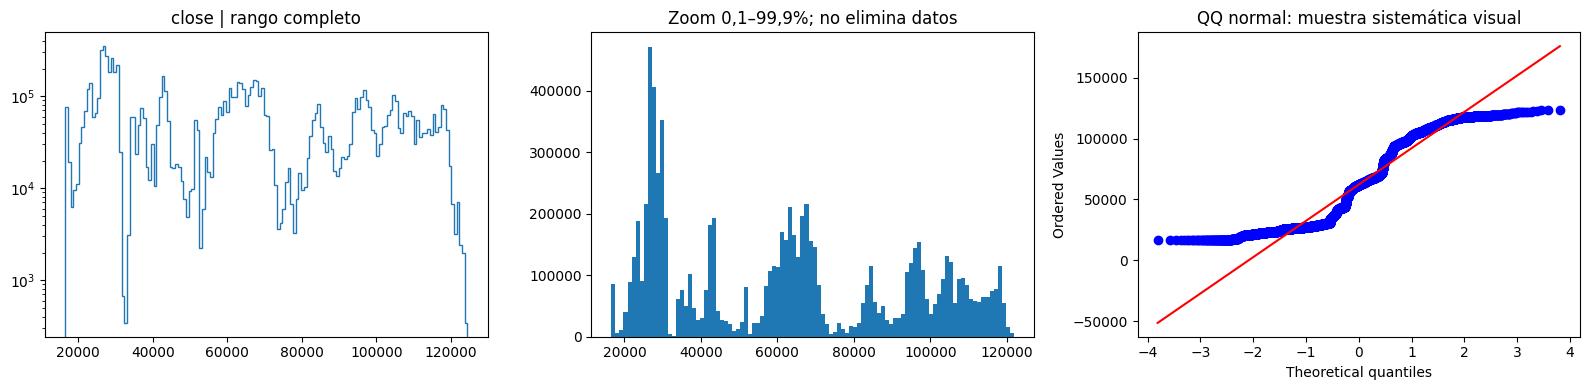

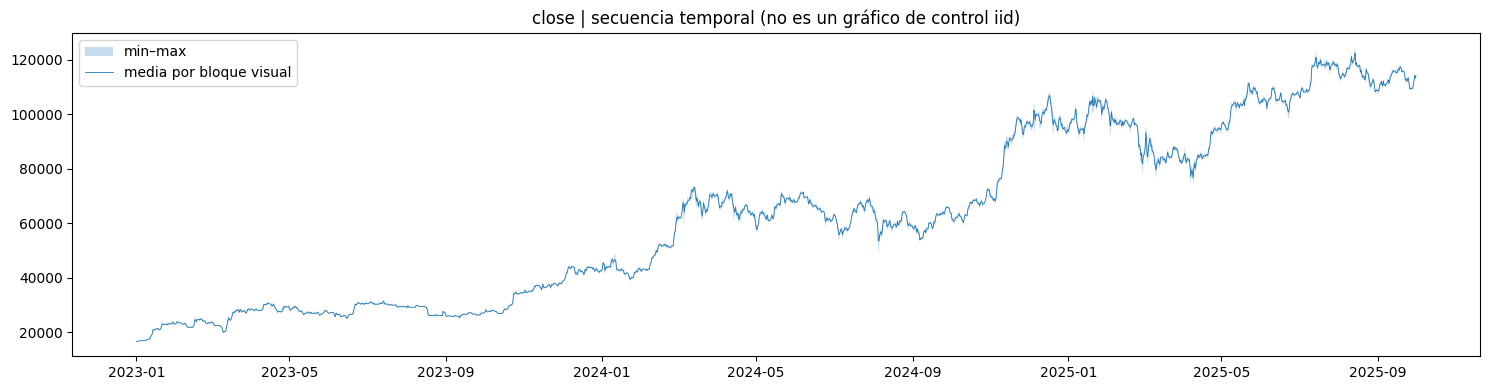

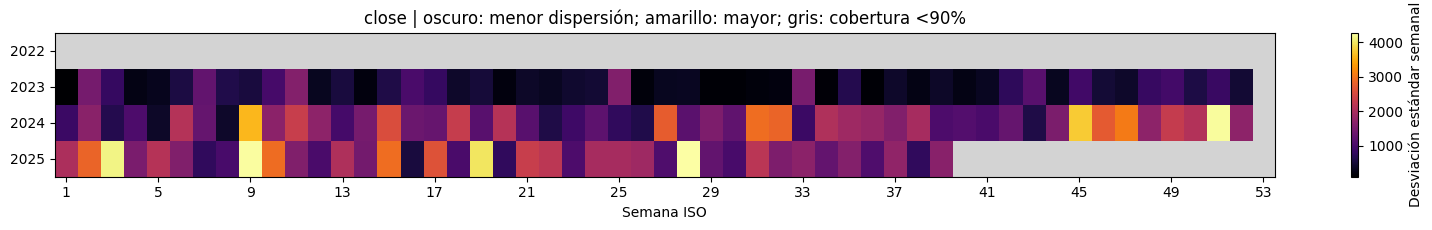

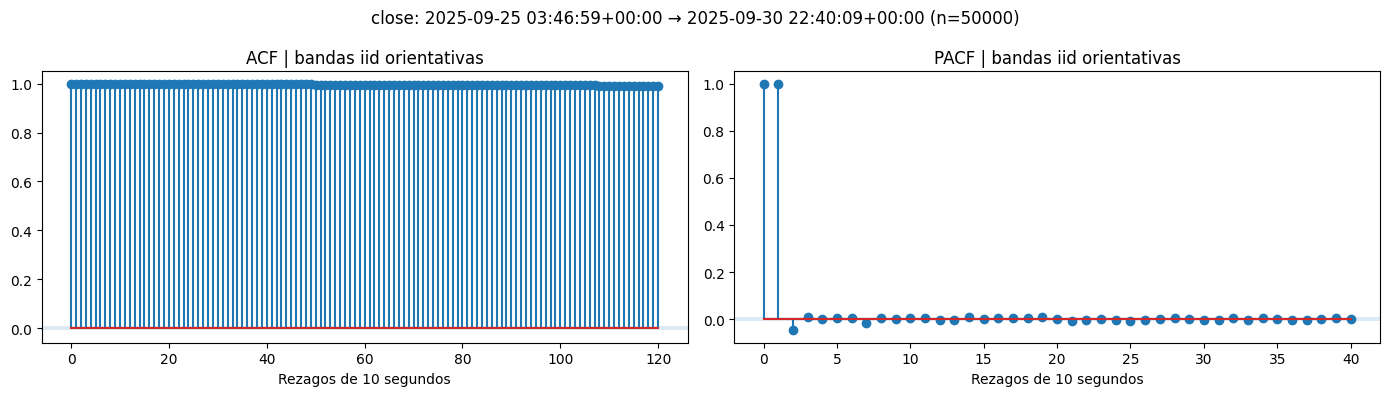

,variable,acf_n,tau,n_effective,block,bootstrap_n,mean_ci_low,mean_ci_high
0,close,50000,239.998293,208.334815,240,5000,113279.801631,113734.956306


,test,lag,p,statistic,start,n,warnings
0,LjungBox_raw,10.0,0.000000e+00,48609.371941,2023-01-01 00:00:19+00:00,5000,NaN
1,LjungBox_raw,30.0,0.000000e+00,139003.737345,2023-01-01 00:00:19+00:00,5000,NaN
2,LjungBox_raw,60.0,0.000000e+00,260335.267486,2023-01-01 00:00:19+00:00,5000,NaN
3,LjungBox_AR5_resid,10.0,3.342767e-02,12.101158,2023-01-01 00:00:19+00:00,5000,NaN
4,LjungBox_AR5_resid,30.0,4.435312e-02,38.187004,2023-01-01 00:00:19+00:00,5000,NaN
5,LjungBox_AR5_resid,60.0,3.788435e-02,74.984837,2023-01-01 00:00:19+00:00,5000,NaN
6,ADF,NaN,1.489390e-01,-2.942282,2023-01-01 00:00:19+00:00,5000,NaN
7,KPSS,NaN,1.000000e-02,1.458731,2023-01-01 00:00:19+00:00,5000,NaN
8,White_LM,NaN,1.746671e-38,186.956876,2023-01-01 00:00:19+00:00,5000,NaN
9,ARCH_LM,NaN,4.277586e-32,202.122573,2023-01-01 00:00:19+00:00,5000,adfuller currently returns a plain tuple whose...


,date,status,F,p_classic,p_HAC,n
0,2024-01-01,ok,1.074245,0.341595,0.458295,9999
1,2025-01-01,ok,0.689138,0.502032,0.547053,9999


,segments,breaks,rss,bic
0,1,0,1004.000000,13.823495
1,2,1,254.122359,-1351.780159
2,3,2,69.457648,-2640.243753
3,4,3,42.880733,-3110.644011
4,5,4,25.602626,-3614.611112
5,6,5,20.365890,-3830.536454


Quiebres aproximados en medias diarias: ['2023-10-30 00:00:00+00:00', '2024-02-25 00:00:00+00:00', '2024-11-13 00:00:00+00:00', '2025-02-25 00:00:00+00:00', '2025-05-08 00:00:00+00:00']


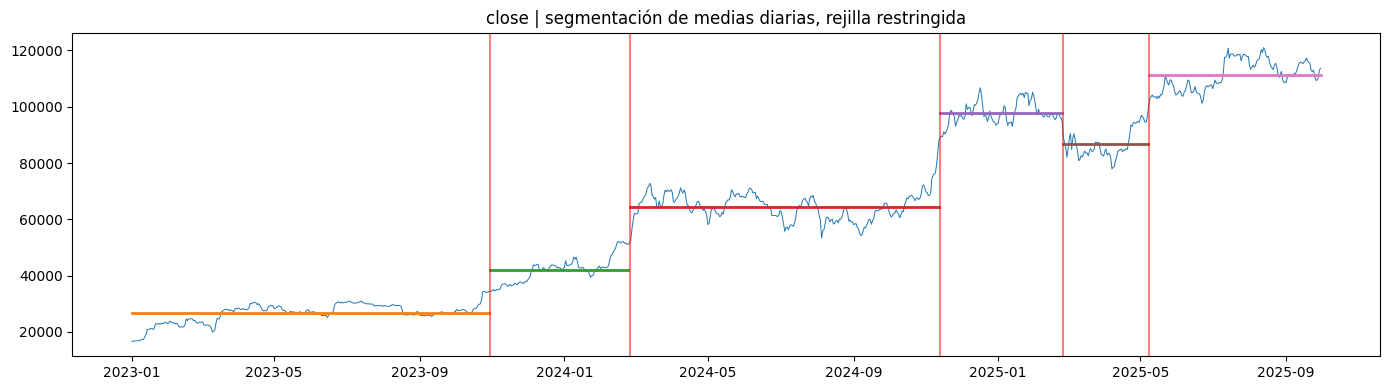

,n,status,valid_origins,similarity_p10,similarity_median,similarity_min,other_pass,pass_70,joint_70,pass_80,joint_80,pass_90,joint_90,pass_95,joint_95,pass_99,joint_99
0,60,ok,23,0.367589,0.367590,0.367588,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,120,ok,23,0.260263,0.260264,0.260262,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,360,ok,23,0.141396,0.141398,0.141395,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2160,ok,23,0.057837,0.074963,0.057835,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8640,ok,23,0.048348,0.061156,0.038704,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,60480,ok,23,0.078314,0.106615,0.059488,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,259200,ok,23,0.102653,0.173544,0.077548,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,777600,ok,22,0.204506,0.235816,0.134380,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,threshold_pct,n_short,n_joint
0,70,NaN,NaN
1,80,NaN,NaN
2,90,NaN,NaN
3,95,NaN,NaN
4,99,NaN,NaN


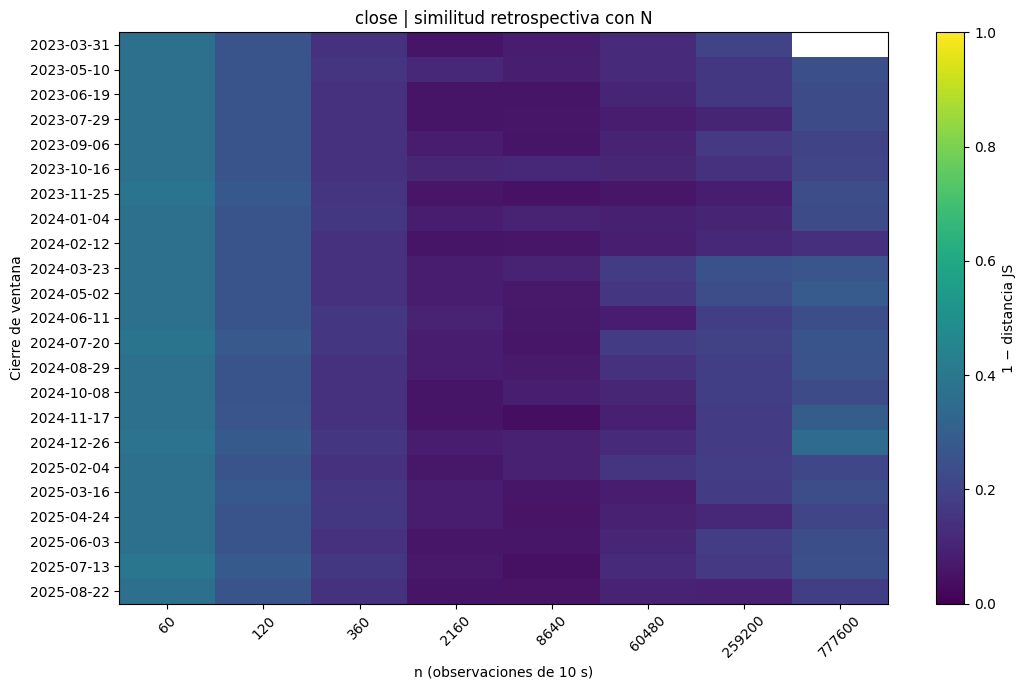

""


,phase,n,model,MSE,MAE,MAPE,QLIKE,folds,RMSE
0,confirmation,60,AR_BIC,321.575333,11.068290,0.010866,NaN,47,17.932522
1,confirmation,60,persistence,291.825391,10.673191,0.010440,NaN,47,17.082898
2,confirmation,120,AR_BIC,282.501039,10.536473,0.010335,NaN,47,16.807767
3,confirmation,120,persistence,291.825391,10.673191,0.010440,NaN,47,17.082898
4,confirmation,360,AR_BIC,293.575488,10.735008,0.010483,NaN,47,17.134045
5,confirmation,360,persistence,291.825391,10.673191,0.010440,NaN,47,17.082898
6,confirmation,2160,AR_BIC,297.198816,11.149944,0.010881,NaN,47,17.239455
7,confirmation,2160,persistence,291.825391,10.673191,0.010440,NaN,47,17.082898
8,confirmation,8640,AR_BIC,301.266988,11.214037,0.010963,NaN,47,17.357044
9,confirmation,8640,persistence,291.825391,10.673191,0.010440,NaN,47,17.082898


n predictivo (solo desarrollo): 60 ; n competitivos: [60, 120, 360, 2160, 8640, 60480, 259200, 777600]


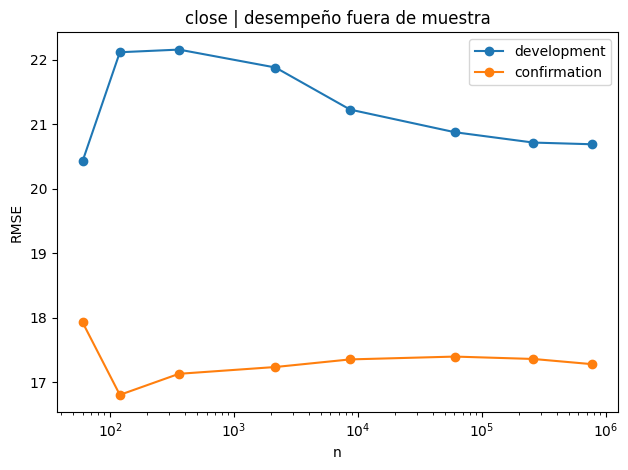

,variable,target,n_short,n_balanced,n_predictive,status
0,close,0.95,None,None,60,sin candidato que cumpla todos los criterios


In [ ]:
result_close = analyze_variable('close')

## close_ln
Logaritmo del cierre a 10 s. Reduce asimetría de escala pero no garantiza estacionariedad. Los cambios de media o tendencia no se eliminan por tomar logaritmos.

Se generan: descriptivos y cuantiles; histograma completo y zoom; QQ; secuencia; calendario semanal; ACF/PACF; bootstrap y tamaño efectivo; Ljung–Box, ADF, KPSS, White, ARCH-LM; Chow y quiebres; similitud histórica y umbrales; sensibilidad; backtest; n corto y equilibrado.


VARIABLE: close_ln


,variable,N_valid,N_grid,missing,mean,std,median,IQR,skew,excess_kurtosis,minimum,maximum,zero_fraction,tukey_outlier_fraction
0,close_ln,8674080,8674082,2,10.89661,0.554582,11.034471,1.150139,-0.234888,-1.311299,9.711145,11.731595,0.0,0.0


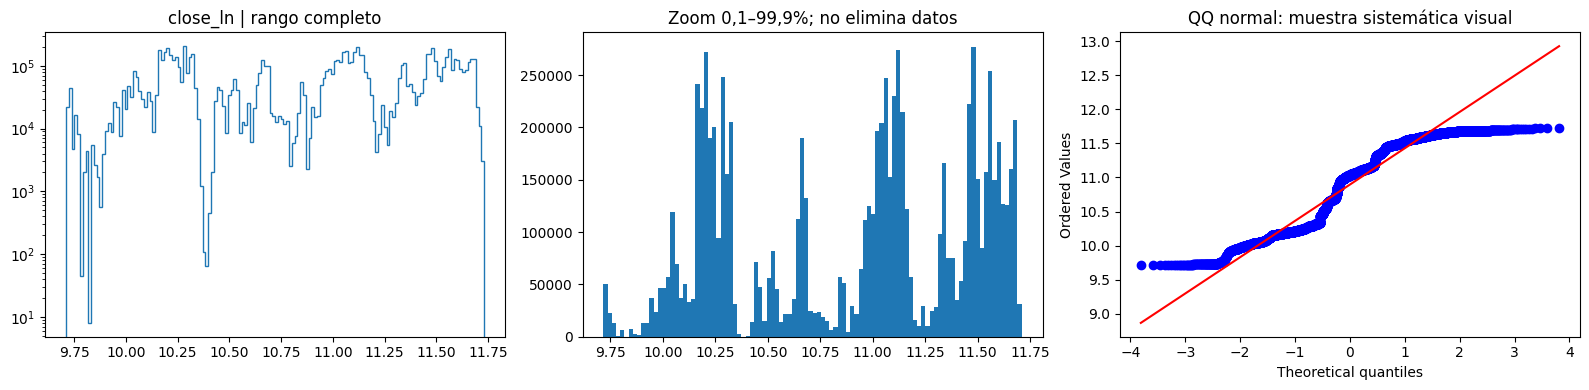

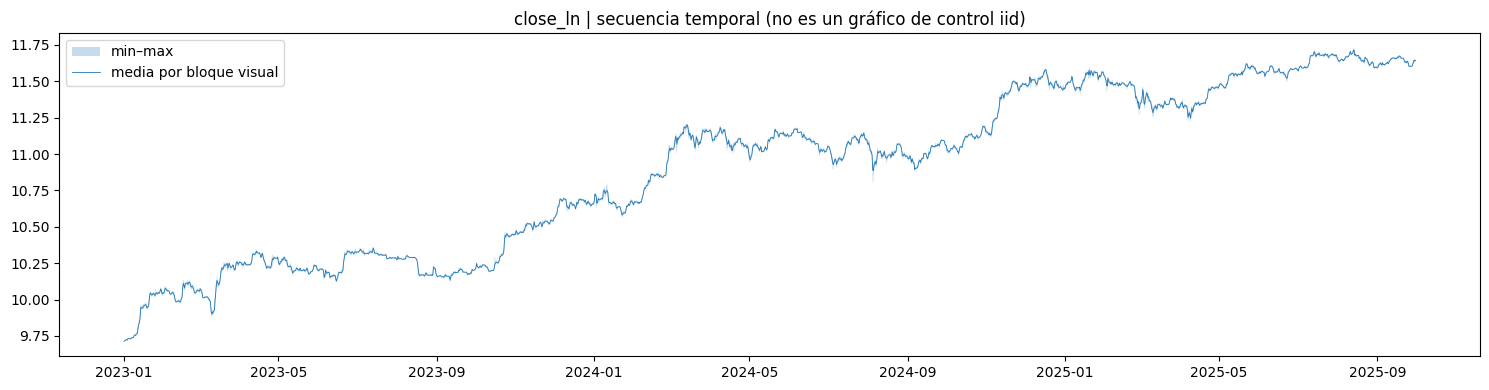

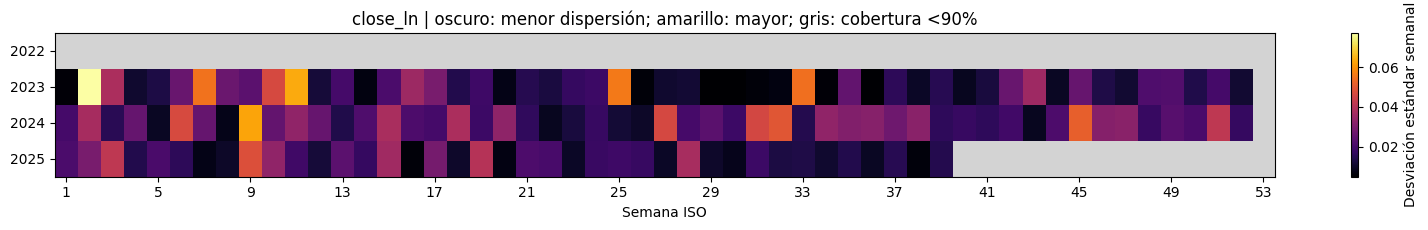

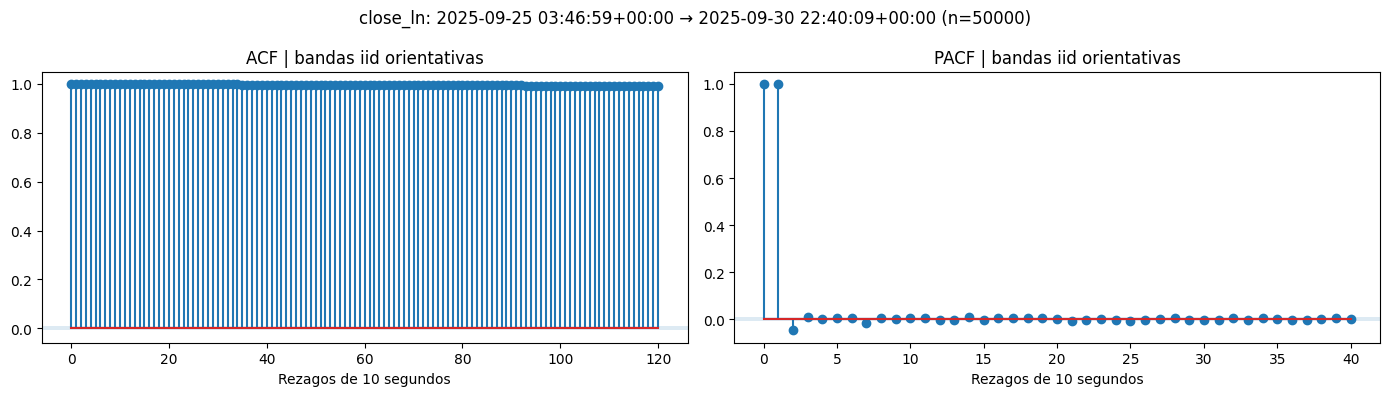

,variable,acf_n,tau,n_effective,block,bootstrap_n,mean_ci_low,mean_ci_high
0,close_ln,50000,239.99454,208.338073,240,5000,11.63779,11.641307


,test,lag,p,statistic,start,n,warnings
0,LjungBox_raw,10.0,0.000000e+00,48608.758221,2023-01-01 00:00:19+00:00,5000,NaN
1,LjungBox_raw,30.0,0.000000e+00,138999.958393,2023-01-01 00:00:19+00:00,5000,NaN
2,LjungBox_raw,60.0,0.000000e+00,260323.562412,2023-01-01 00:00:19+00:00,5000,NaN
3,LjungBox_AR5_resid,10.0,3.388062e-02,12.067041,2023-01-01 00:00:19+00:00,5000,NaN
4,LjungBox_AR5_resid,30.0,4.479866e-02,38.142720,2023-01-01 00:00:19+00:00,5000,NaN
5,LjungBox_AR5_resid,60.0,3.793611e-02,74.976760,2023-01-01 00:00:19+00:00,5000,NaN
6,ADF,NaN,1.488210e-01,-2.942669,2023-01-01 00:00:19+00:00,5000,NaN
7,KPSS,NaN,1.000000e-02,1.458533,2023-01-01 00:00:19+00:00,5000,NaN
8,White_LM,NaN,1.230512e-38,187.668719,2023-01-01 00:00:19+00:00,5000,NaN
9,ARCH_LM,NaN,3.200454e-32,202.758730,2023-01-01 00:00:19+00:00,5000,adfuller currently returns a plain tuple whose...


,date,status,F,p_classic,p_HAC,n
0,2024-01-01,ok,1.074728,0.341430,0.458155,9999
1,2025-01-01,ok,0.693914,0.499641,0.548364,9999


,segments,breaks,rss,bic
0,1,0,1004.000000,13.823495
1,2,1,191.116740,-1637.851316
2,3,2,77.006574,-2536.657443
3,4,3,40.245711,-3174.316855
4,5,4,28.290316,-3514.387188
5,6,5,19.705616,-3863.626031


Quiebres aproximados en medias diarias: ['2023-03-14 00:00:00+00:00', '2023-10-30 00:00:00+00:00', '2024-02-18 00:00:00+00:00', '2024-11-06 00:00:00+00:00', '2025-05-08 00:00:00+00:00']


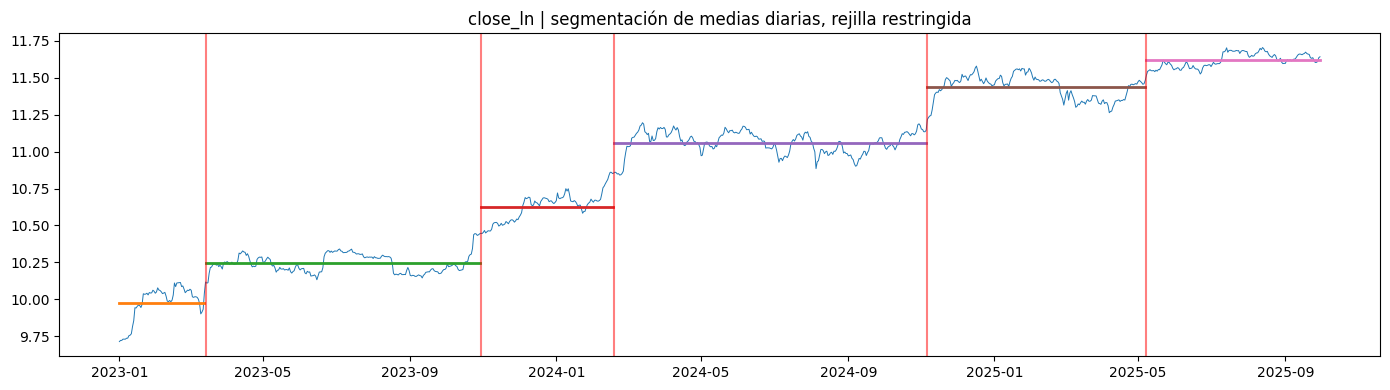

,n,status,valid_origins,similarity_p10,similarity_median,similarity_min,other_pass,pass_70,joint_70,pass_80,joint_80,pass_90,joint_90,pass_95,joint_95,pass_99,joint_99
0,60,ok,23,0.367589,0.367590,0.367588,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,120,ok,23,0.260263,0.260264,0.260262,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,360,ok,23,0.141396,0.141398,0.141395,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2160,ok,23,0.057837,0.074963,0.057835,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8640,ok,23,0.048348,0.061156,0.038704,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,60480,ok,23,0.078314,0.106615,0.059488,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,259200,ok,23,0.102653,0.173544,0.077548,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,777600,ok,22,0.204506,0.235816,0.134380,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,threshold_pct,n_short,n_joint
0,70,NaN,NaN
1,80,NaN,NaN
2,90,NaN,NaN
3,95,NaN,NaN
4,99,NaN,NaN


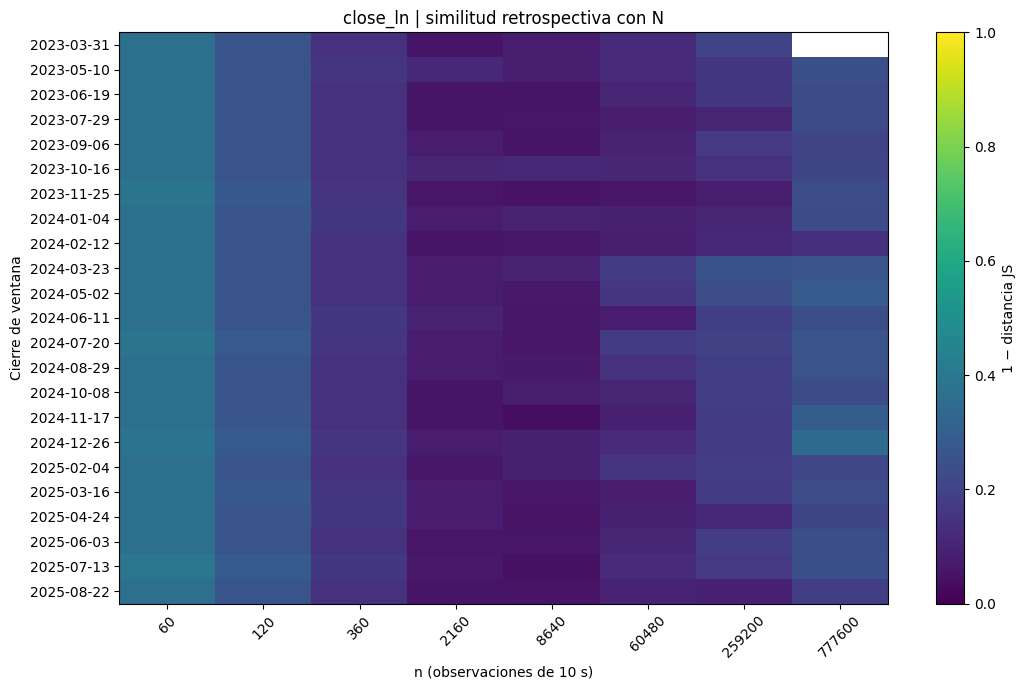

""


,phase,n,model,MSE,MAE,MAPE,QLIKE,folds,RMSE
0,confirmation,60,AR_BIC,3.122267e-08,0.000109,0.000943,NaN,47,0.000177
1,confirmation,60,persistence,2.667113e-08,0.000104,0.000906,NaN,47,0.000163
2,confirmation,120,AR_BIC,2.638764e-08,0.000103,0.000897,NaN,47,0.000162
3,confirmation,120,persistence,2.667113e-08,0.000104,0.000906,NaN,47,0.000163
4,confirmation,360,AR_BIC,2.694269e-08,0.000105,0.000909,NaN,47,0.000164
5,confirmation,360,persistence,2.667113e-08,0.000104,0.000906,NaN,47,0.000163
6,confirmation,2160,AR_BIC,2.710319e-08,0.000109,0.000944,NaN,47,0.000165
7,confirmation,2160,persistence,2.667113e-08,0.000104,0.000906,NaN,47,0.000163
8,confirmation,8640,AR_BIC,2.762038e-08,0.000110,0.000951,NaN,47,0.000166
9,confirmation,8640,persistence,2.667113e-08,0.000104,0.000906,NaN,47,0.000163


n predictivo (solo desarrollo): 60 ; n competitivos: [60, 120, 360, 2160, 8640, 60480, 259200, 777600]


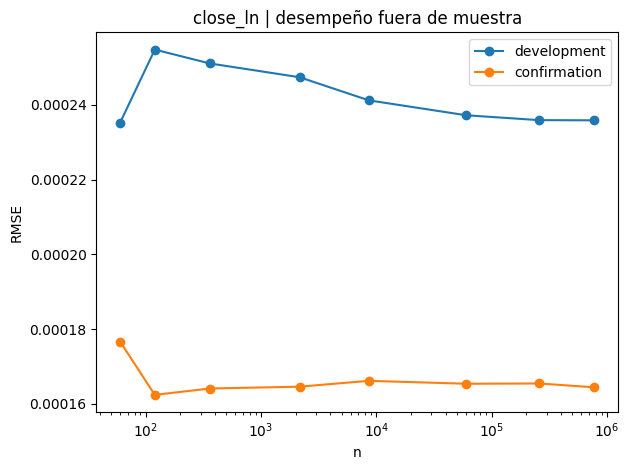

,variable,target,n_short,n_balanced,n_predictive,status
0,close_ln,0.95,None,None,60,sin candidato que cumpla todos los criterios


In [ ]:
result_close_ln = analyze_variable('close_ln')

## diff_close_ln
Retorno logarítmico entre cierres consecutivos de 10 s. Examinar colas, ceros, autocorrelación de retornos y heterocedasticidad de residuos. Los retornos que atraviesan huecos se excluyen; no se consideran cero.

Se generan: descriptivos y cuantiles; histograma completo y zoom; QQ; secuencia; calendario semanal; ACF/PACF; bootstrap y tamaño efectivo; Ljung–Box, ADF, KPSS, White, ARCH-LM; Chow y quiebres; similitud histórica y umbrales; sensibilidad; backtest; n corto y equilibrado.


VARIABLE: diff_close_ln


,variable,N_valid,N_grid,missing,mean,std,median,IQR,skew,excess_kurtosis,minimum,maximum,zero_fraction,tukey_outlier_fraction
0,diff_close_ln,8674079,8674082,3,2.226009e-07,0.000256,0.0,0.000122,-0.428667,85.217787,-0.021913,0.015635,0.172032,0.179357


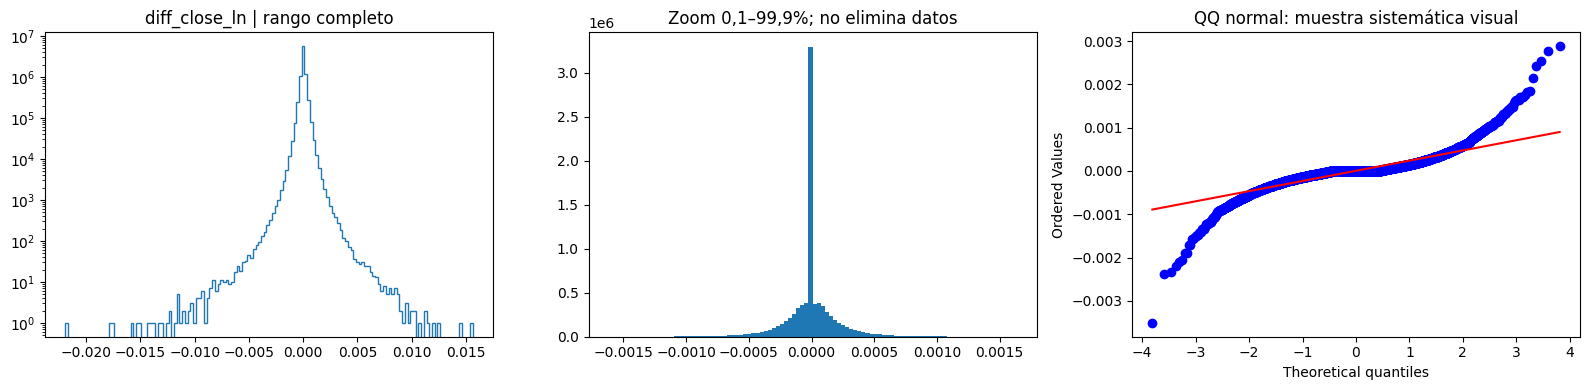

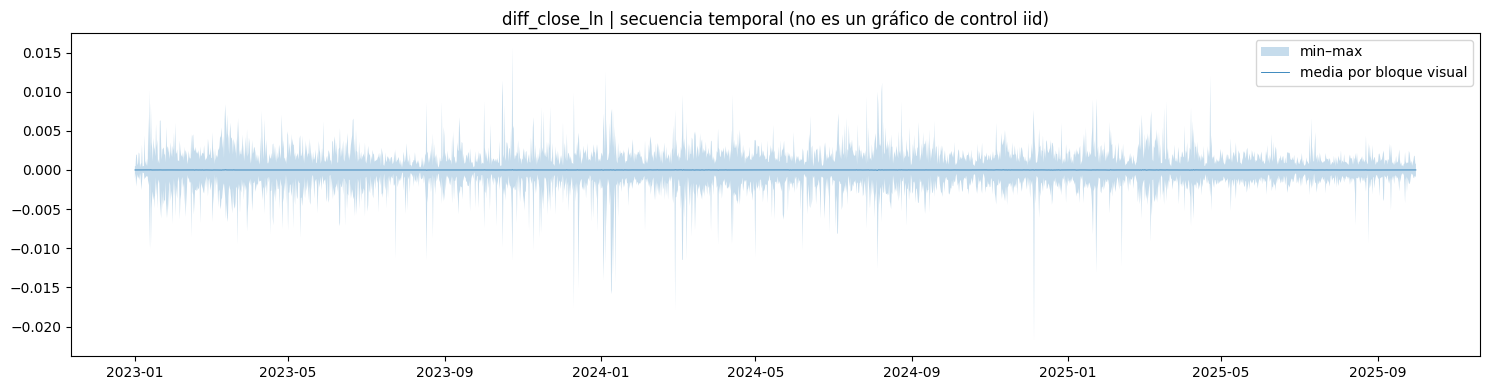

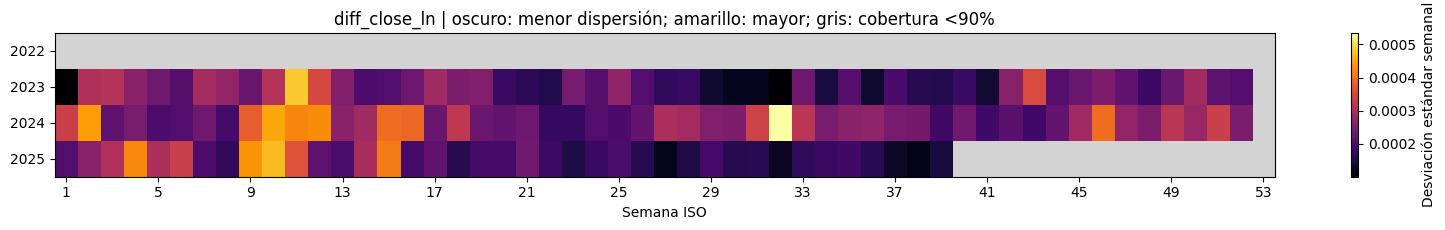

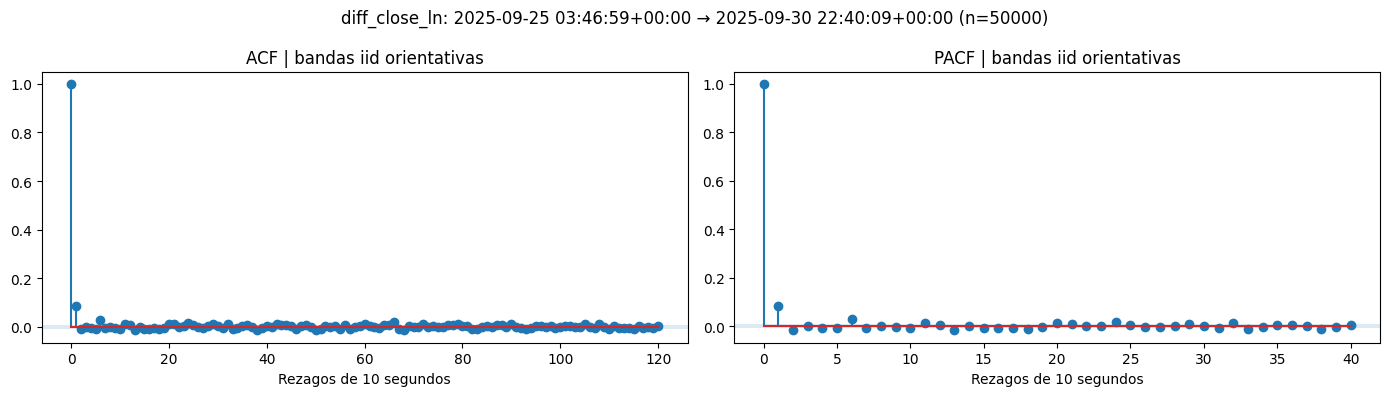

,variable,acf_n,tau,n_effective,block,bootstrap_n,mean_ci_low,mean_ci_high
0,diff_close_ln,50000,1.145848,43635.794692,2,5000,-0.000004,0.000006


,test,lag,p,statistic,start,n,warnings
0,LjungBox_raw,10.0,1.778164e-02,21.513933,2023-01-01 00:00:29+00:00,5000,NaN
1,LjungBox_raw,30.0,2.267735e-02,47.411223,2023-01-01 00:00:29+00:00,5000,NaN
2,LjungBox_raw,60.0,2.499341e-02,83.299209,2023-01-01 00:00:29+00:00,5000,NaN
3,LjungBox_AR5_resid,10.0,7.450003e-02,10.026066,2023-01-01 00:00:29+00:00,5000,NaN
4,LjungBox_AR5_resid,30.0,5.855169e-02,36.935782,2023-01-01 00:00:29+00:00,5000,NaN
5,LjungBox_AR5_resid,60.0,4.128263e-02,74.473689,2023-01-01 00:00:29+00:00,5000,NaN
6,ADF,NaN,0.000000e+00,-72.519938,2023-01-01 00:00:29+00:00,5000,NaN
7,KPSS,NaN,1.000000e-01,0.047198,2023-01-01 00:00:29+00:00,5000,NaN
8,White_LM,NaN,5.567178e-38,184.600885,2023-01-01 00:00:29+00:00,5000,NaN
9,ARCH_LM,NaN,6.031931e-32,201.368667,2023-01-01 00:00:29+00:00,5000,adfuller currently returns a plain tuple whose...


,date,status,F,p_classic,p_HAC,n
0,2024-01-01,ok,0.087945,0.915812,0.923504,9999
1,2025-01-01,ok,1.791339,0.166790,0.373538,9999


,segments,breaks,rss,bic
0,1,0,1004.000000,13.823495
1,2,1,997.414128,21.039422
2,3,2,993.730115,31.147713
3,4,3,987.348751,38.503104
4,5,4,984.830766,49.762878
5,6,5,979.889849,58.536605


Quiebres aproximados en medias diarias: []


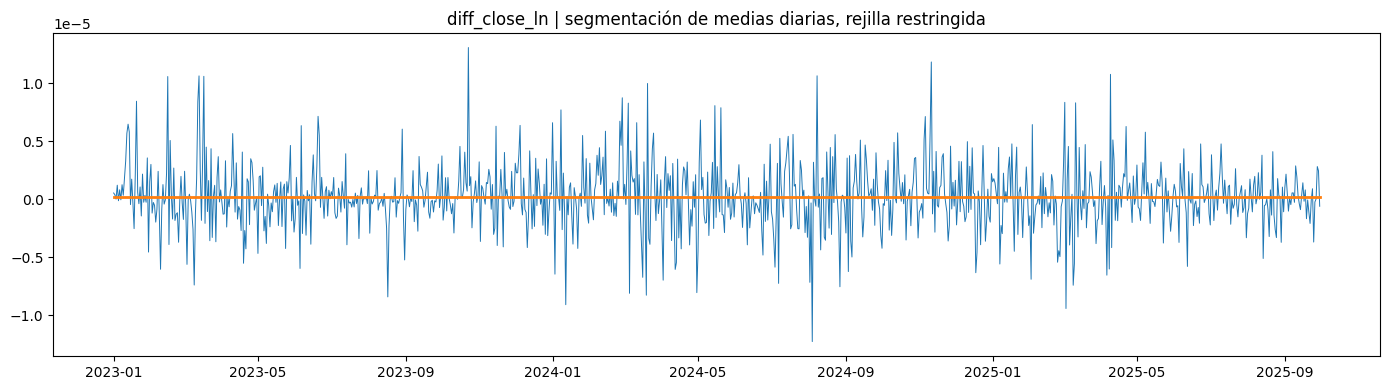

,n,status,valid_origins,similarity_p10,similarity_median,similarity_min,other_pass,pass_70,joint_70,pass_80,joint_80,pass_90,joint_90,pass_95,joint_95,pass_99,joint_99
0,60,ok,23,0.612623,0.657487,0.573276,0.0,0.217391,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,120,ok,23,0.556814,0.670833,0.489132,0.0,0.130435,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,360,ok,23,0.492291,0.669372,0.444489,0.0,0.260870,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2160,ok,23,0.472465,0.680383,0.394246,0.0,0.347826,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8640,ok,23,0.547900,0.668943,0.470629,0.0,0.304348,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,60480,ok,23,0.614562,0.685537,0.534848,0.0,0.478261,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,259200,ok,23,0.639094,0.719697,0.610117,0.0,0.608696,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,777600,ok,22,0.691669,0.742880,0.615433,0.0,0.818182,0.0,0.045455,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,threshold_pct,n_short,n_joint
0,70,NaN,NaN
1,80,NaN,NaN
2,90,NaN,NaN
3,95,NaN,NaN
4,99,NaN,NaN


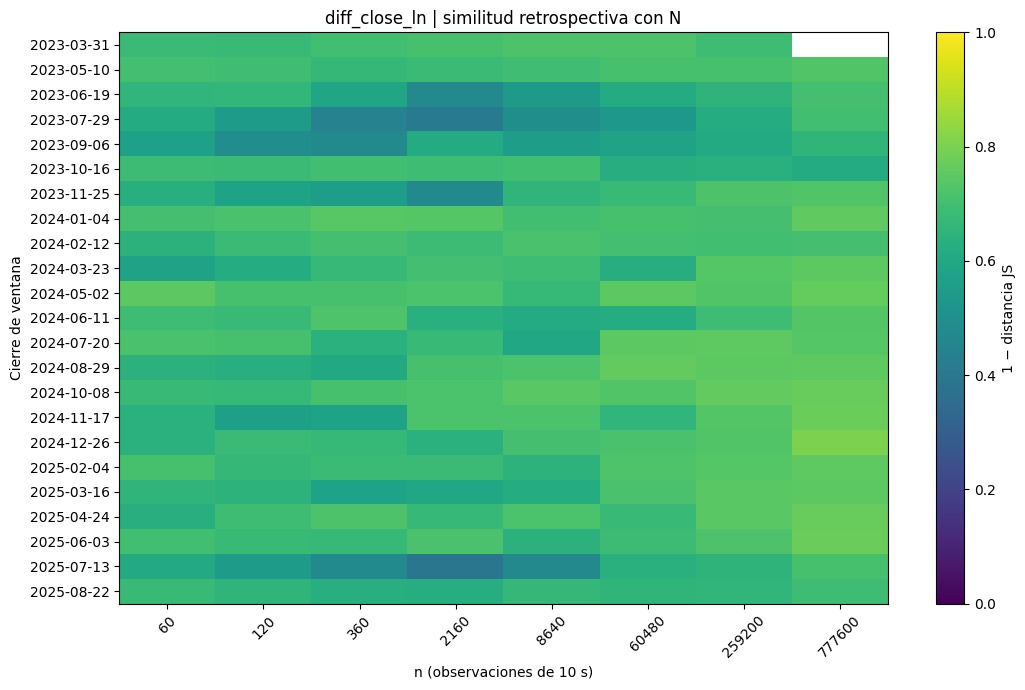

""


,phase,n,model,MSE,MAE,MAPE,QLIKE,folds,RMSE
0,confirmation,60,AR_BIC,3.149622e-08,0.000115,NaN,NaN,47,0.000177
1,confirmation,60,persistence,6.175363e-08,0.000163,NaN,NaN,47,0.000249
2,confirmation,60,zero,2.667113e-08,0.000104,NaN,NaN,47,0.000163
3,confirmation,120,AR_BIC,2.985594e-08,0.000112,NaN,NaN,47,0.000173
4,confirmation,120,persistence,6.175363e-08,0.000163,NaN,NaN,47,0.000249
5,confirmation,120,zero,2.667113e-08,0.000104,NaN,NaN,47,0.000163
6,confirmation,360,AR_BIC,3.021578e-08,0.000113,NaN,NaN,47,0.000174
7,confirmation,360,persistence,6.175363e-08,0.000163,NaN,NaN,47,0.000249
8,confirmation,360,zero,2.667113e-08,0.000104,NaN,NaN,47,0.000163
9,confirmation,2160,AR_BIC,2.799196e-08,0.000109,NaN,NaN,47,0.000167


n predictivo (solo desarrollo): 60 ; n competitivos: [60, 120, 8640, 60480, 259200, 777600]


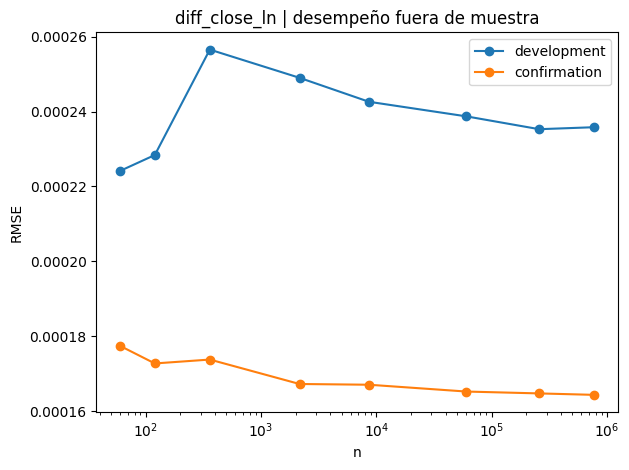

,variable,target,n_short,n_balanced,n_predictive,status
0,diff_close_ln,0.95,None,None,60,sin candidato que cumpla todos los criterios


In [ ]:
result_diff_close_ln = analyze_variable('diff_close_ln')

## r2
Suma de diez cuadrados de retornos logarítmicos de 1 s. Es no negativa, puede tener masa en cero, asimetría y persistencia. El ruido de microestructura puede inflar la variación realizada a alta frecuencia. No se interpreta como volatilidad anualizada. La desviación semanal de r2 mide variabilidad de la variación realizada, no directamente volatilidad del precio.

Se generan: descriptivos y cuantiles; histograma completo y zoom; QQ; secuencia; calendario semanal; ACF/PACF; bootstrap y tamaño efectivo; Ljung–Box, ADF, KPSS, White, ARCH-LM; Chow y quiebres; similitud histórica y umbrales; sensibilidad; backtest; n corto y equilibrado.


VARIABLE: r2


,variable,N_valid,N_grid,missing,mean,std,median,IQR,skew,excess_kurtosis,minimum,maximum,zero_fraction,tukey_outlier_fraction
0,r2,8674080,8674082,2,5.053935e-08,3.749492e-07,6.134076e-09,3.430486e-08,157.937489,49338.758699,0.0,0.000184,0.004878,0.121466


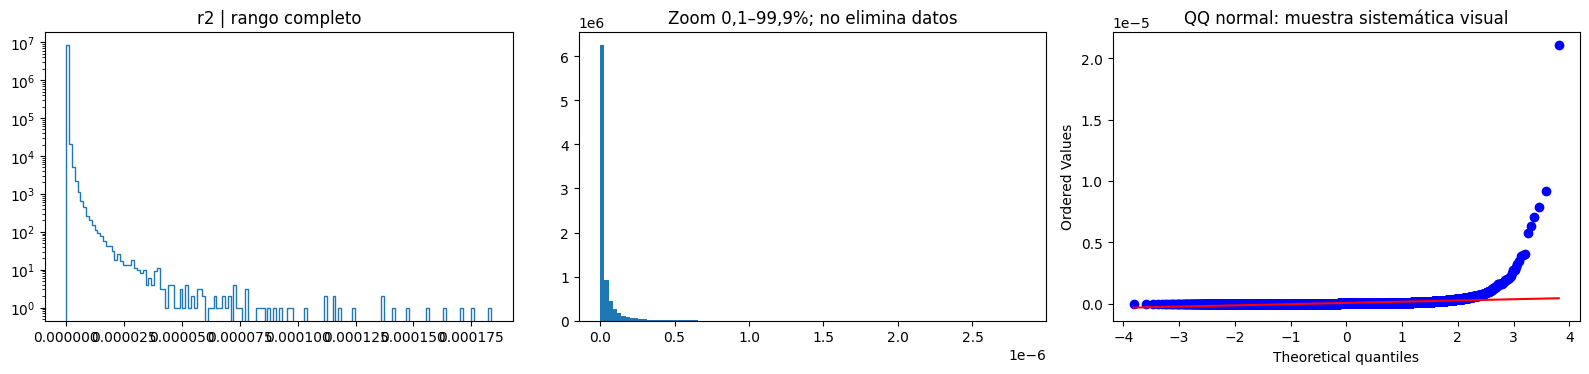

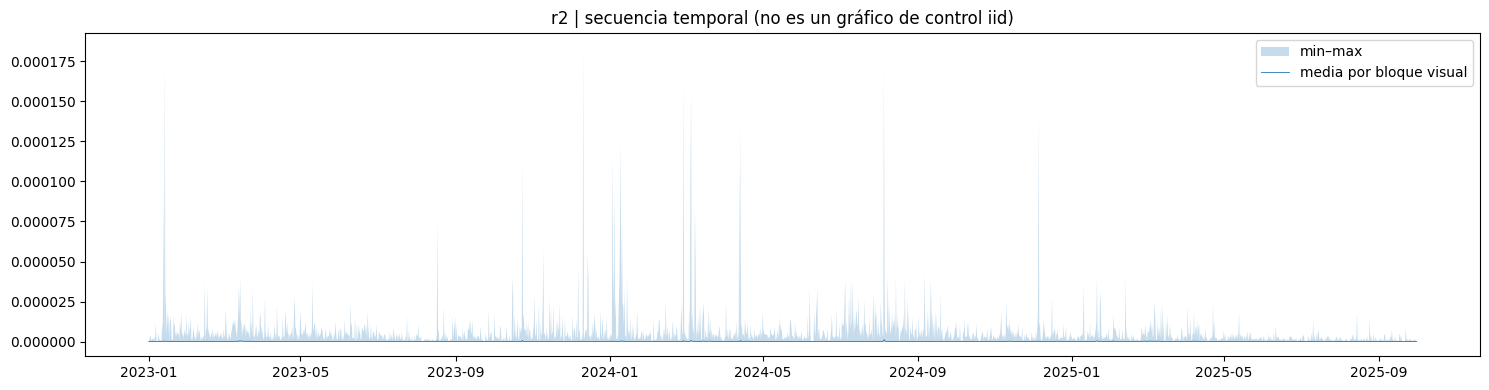

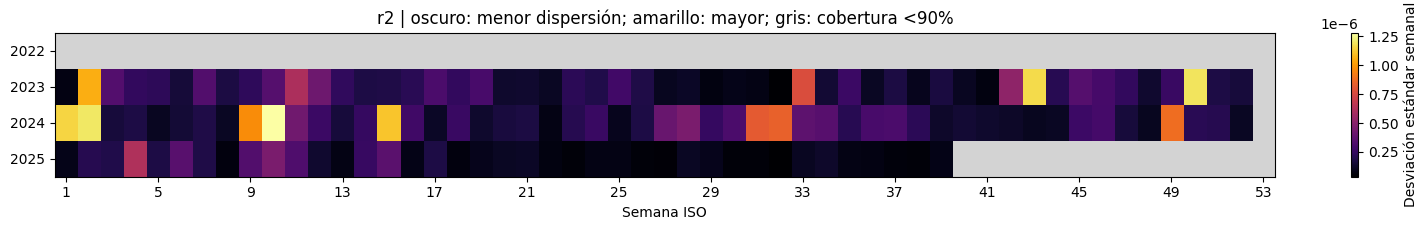

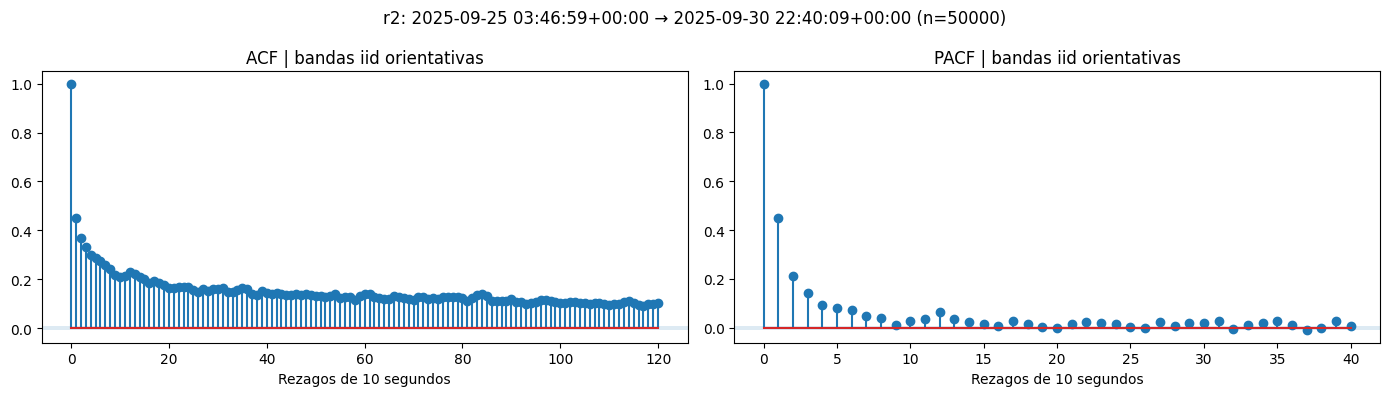

,variable,acf_n,tau,n_effective,block,bootstrap_n,mean_ci_low,mean_ci_high
0,r2,50000,36.086092,1385.575362,37,5000,1.363137e-08,1.844536e-08


,test,lag,p,statistic,start,n,warnings
0,LjungBox_raw,10.0,2.331593e-42,223.158142,2023-01-01 00:00:19+00:00,5000,NaN
1,LjungBox_raw,30.0,4.630261e-41,273.262709,2023-01-01 00:00:19+00:00,5000,NaN
2,LjungBox_raw,60.0,1.158768e-69,494.839033,2023-01-01 00:00:19+00:00,5000,NaN
3,LjungBox_AR5_resid,10.0,1.309547e-01,8.495602,2023-01-01 00:00:19+00:00,5000,NaN
4,LjungBox_AR5_resid,30.0,4.451153e-01,25.309945,2023-01-01 00:00:19+00:00,5000,NaN
5,LjungBox_AR5_resid,60.0,2.470997e-18,199.937951,2023-01-01 00:00:19+00:00,5000,NaN
6,ADF,NaN,0.000000e+00,-35.430049,2023-01-01 00:00:19+00:00,5000,NaN
7,KPSS,NaN,1.000000e-02,1.208616,2023-01-01 00:00:19+00:00,5000,NaN
8,White_LM,NaN,4.727890e-01,3.533592,2023-01-01 00:00:19+00:00,5000,NaN
9,ARCH_LM,NaN,9.999999e-01,1.990508,2023-01-01 00:00:19+00:00,5000,adfuller currently returns a plain tuple whose...


,date,status,F,p_classic,p_HAC,n
0,2024-01-01,ok,13.869965,9.653714e-07,5.450551e-03,9999
1,2025-01-01,ok,160.148589,3.463523e-69,1.063765e-22,9999


,segments,breaks,rss,bic
0,1,0,1004.000000,13.823495
1,2,1,958.509352,-18.906464
2,3,2,927.369524,-38.242287
3,4,3,893.928975,-61.291480
4,5,4,863.187617,-82.602220
5,6,5,835.033108,-102.072062


Quiebres aproximados en medias diarias: ['2023-03-08 00:00:00+00:00', '2023-03-28 00:00:00+00:00', '2024-02-25 00:00:00+00:00', '2024-03-22 00:00:00+00:00', '2025-04-12 00:00:00+00:00']


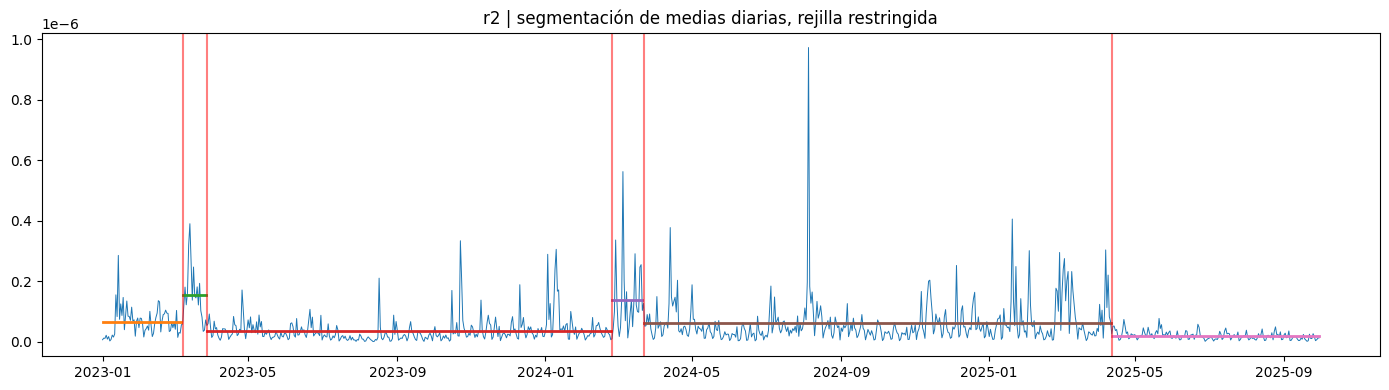

,n,status,valid_origins,similarity_p10,similarity_median,similarity_min,other_pass,pass_70,joint_70,pass_80,joint_80,pass_90,joint_90,pass_95,joint_95,pass_99,joint_99
0,60,ok,23,0.567866,0.636766,0.506526,0.0,0.043478,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,120,ok,23,0.495630,0.608575,0.413986,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,360,ok,23,0.416235,0.598559,0.370581,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2160,ok,23,0.374427,0.606585,0.314513,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8640,ok,23,0.448846,0.579406,0.382838,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,60480,ok,23,0.516853,0.617277,0.471126,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,259200,ok,23,0.546762,0.652034,0.520600,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,777600,ok,22,0.580865,0.684061,0.533461,0.0,0.181818,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,threshold_pct,n_short,n_joint
0,70,NaN,NaN
1,80,NaN,NaN
2,90,NaN,NaN
3,95,NaN,NaN
4,99,NaN,NaN


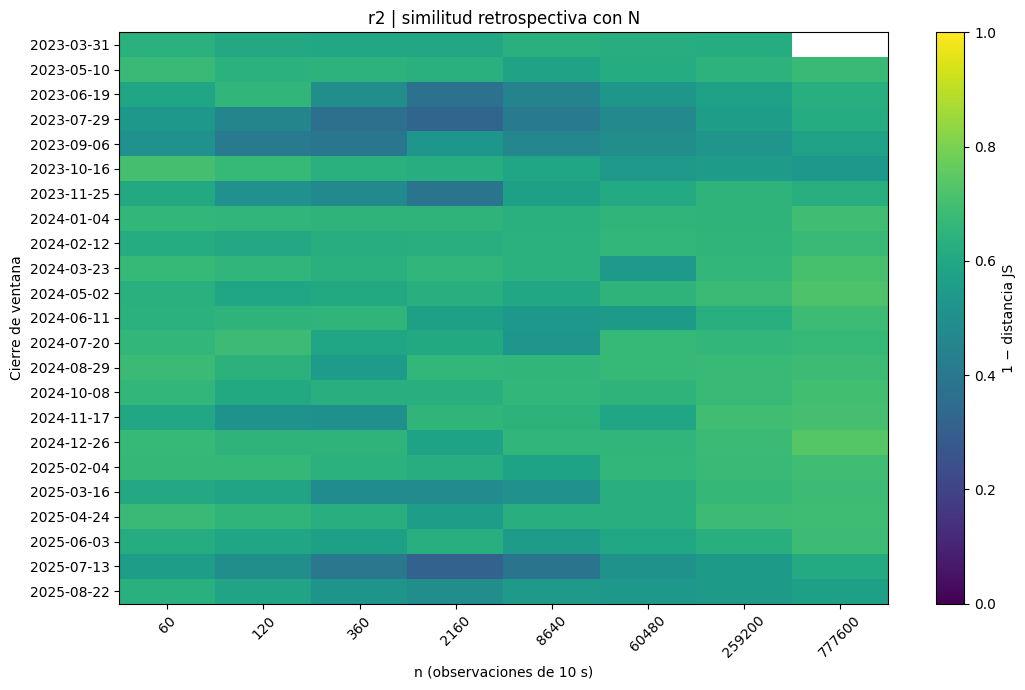

""


,phase,n,model,MSE,MAE,MAPE,QLIKE,folds,RMSE
0,confirmation,60,AR_BIC,3.931436e-15,2.623649e-08,NaN,-1.690454e+01,47,6.270117e-08
1,confirmation,60,persistence,2.462201e-15,2.188419e-08,NaN,2.548324e+05,47,4.962057e-08
2,confirmation,60,train_mean,4.176723e-15,2.783752e-08,NaN,-1.691728e+01,47,6.462757e-08
3,confirmation,120,AR_BIC,3.134921e-15,2.536779e-08,NaN,-1.629987e+01,47,5.599037e-08
4,confirmation,120,persistence,2.462201e-15,2.188419e-08,NaN,2.548324e+05,47,4.962057e-08
5,confirmation,120,train_mean,3.943351e-15,2.894612e-08,NaN,-1.656333e+01,47,6.279610e-08
6,confirmation,360,AR_BIC,2.735682e-15,2.474660e-08,NaN,-1.654539e+01,47,5.230374e-08
7,confirmation,360,persistence,2.462201e-15,2.188419e-08,NaN,2.548324e+05,47,4.962057e-08
8,confirmation,360,train_mean,3.277444e-15,2.729868e-08,NaN,-1.662370e+01,47,5.724896e-08
9,confirmation,2160,AR_BIC,2.338684e-15,2.273274e-08,NaN,-1.695530e+01,47,4.835994e-08


n predictivo (solo desarrollo): 360 ; n competitivos: [360]


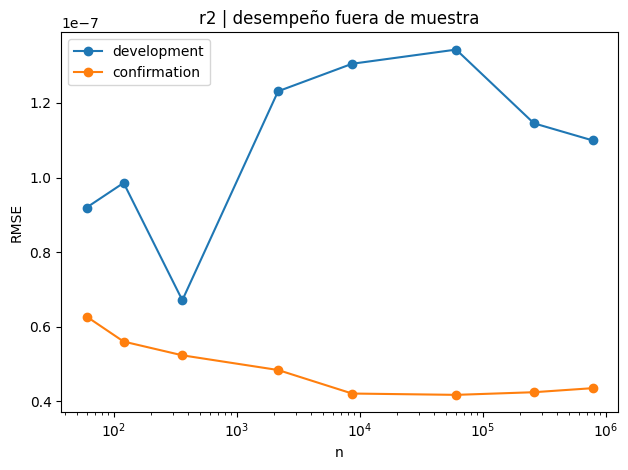

,variable,target,n_short,n_balanced,n_predictive,status
0,r2,0.95,None,None,360,sin candidato que cumpla todos los criterios


In [ ]:
result_r2 = analyze_variable('r2')

## 6. Síntesis conjunta, multiplicidad y lectura final
La ventana común se obtiene intersectando **todos los candidatos elegibles**, no tomando el máximo de los n elegidos por separado: los criterios no tienen por qué ser monótonos en n. Si la intersección está vacía, se informa que no hay solución común en la rejilla ensayada.

Corrección Benjamini–Hochberg sobre los p-valores recolectados. Los p de KPSS están acotados por tablas y la dependencia entre pruebas requiere prudencia; BH se usa como filtro exploratorio, no garantía universal. La selección de n utiliza tamaños de efecto y backtest, no un concurso de p-valores.

**Cómo cerrar el estudio después de ejecutarlo:** comprobar calidad/cobertura; contrastar ADF y KPSS sin confundir no rechazo con prueba de H₀; leer efectos y gráficos junto con significación; revisar diferencias por régimen; comparar contra baselines; exigir estabilidad en confirmación; refinar la rejilla alrededor de candidatos con una nueva validación temporal si se modifica el diseño. Reportar también ausencia de candidatos, sensibilidad a bins y resolución de 10 s. No usar el histórico retrospectivo contra N como prueba de predicción futura.

In [ ]:
final=pd.DataFrame([{k:v for k,v in d.items() if k!='feasible_balanced'} for d in RESULTS.values()])
display(final); save_frame(final,'seleccion_final_por_variable')
if set(RESULTS)==set(VARIABLES):
    common=set.intersection(*(set(RESULTS[v]['feasible_balanced']) for v in VARIABLES))
    common_n=min(common) if common else None
    print('n equilibrado común retrospectivo:',common_n)
    print('Duración:',pd.Timedelta(seconds=10*common_n) if common_n else 'No existe en la rejilla evaluada.')
    (OUT/'seleccion_comun.json').write_text(json.dumps(dict(n=common_n,candidates=sorted(common)),indent=2))
if PVALUES:
    pv=pd.DataFrame(PVALUES)
    ok=np.isfinite(pv.p)
    pv.loc[ok,'q_BH']=multipletests(pv.loc[ok,'p'],method='fdr_bh')[1]
    pv['reject_BH_05']=pv.q_BH<.05
    display(pv); save_frame(pv,'tests_multiplicidad_BH')
print('Resultados guardados en:',OUT)
# con.close()  # cerrar manualmente al terminar; permite volver a ejecutar secciones antes.


,variable,target,n_short,n_balanced,n_predictive,status
0,close,0.95,None,None,60,sin candidato que cumpla todos los criterios
1,close_ln,0.95,None,None,60,sin candidato que cumpla todos los criterios
2,diff_close_ln,0.95,None,None,60,sin candidato que cumpla todos los criterios
3,r2,0.95,None,None,360,sin candidato que cumpla todos los criterios


n equilibrado común retrospectivo: None
Duración: No existe en la rejilla evaluada.


,variable,test,p,start,date,q_BH,reject_BH_05
0,close,LjungBox_raw,0.000000e+00,2023-01-01 00:00:19+00:00,NaN,0.000000e+00,True
1,close,LjungBox_raw,0.000000e+00,2023-01-01 00:00:19+00:00,NaN,0.000000e+00,True
2,close,LjungBox_raw,0.000000e+00,2023-01-01 00:00:19+00:00,NaN,0.000000e+00,True
3,close,LjungBox_AR5_resid,3.342767e-02,2023-01-01 00:00:19+00:00,NaN,4.719200e-02,True
4,close,LjungBox_AR5_resid,4.435312e-02,2023-01-01 00:00:19+00:00,NaN,6.063465e-02,False
...,...,...,...,...,...,...,...
211,r2,ARCH_LM,1.573673e-01,2025-09-30 08:46:59+00:00,NaN,1.909626e-01,False
212,r2,Chow_classic,9.653714e-07,NaN,2024-01-01,2.024468e-06,True
213,r2,Chow_HAC,5.450551e-03,NaN,2024-01-01,9.056300e-03,True
214,r2,Chow_classic,3.463523e-69,NaN,2025-01-01,1.466904e-68,True


Resultados guardados en: /content/drive/MyDrive/Neural/BTC/LSTM+/EDA_close_10s_resultados


## Referencias metodológicas y reproducibilidad
- [DuckDB: procesamiento mayor que RAM](https://duckdb.org/docs/stable/guides/performance/how_to_tune_workloads.html).
- [PyArrow: lectura de esquema Parquet](https://arrow.apache.org/docs/python/generated/pyarrow.parquet.read_schema.html).
- [Statsmodels: tests y diagnósticos](https://www.statsmodels.org/stable/stats.html).
- [SciPy: distancia Jensen–Shannon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.jensenshannon.html).
- [strucchange: documentación del paquete](https://cran.r-project.org/web/packages/strucchange/index.html).

**Presupuesto:** el parquet original se escanea en disco; la tabla de 10 s queda en DuckDB y Parquet. Cada sección carga una sola variable y su índice. Para tres años completos, aproximadamente 9,5 millones de bloques: el vector float64 ocupa ~76 MB, pero índices, cuantiles, máscaras, gráficos y matrices del modelo elevan el pico real a varios cientos de MB o más. El límite de DuckDB no limita NumPy/pandas. Reducir orígenes y ventanas diagnósticas ahorra CPU; para RAM más restringida adaptar también las funciones sobre la serie a procesamiento por lotes. No hay garantía de RAM total de 1 GB.

**Costos explícitos:** ordenación a 1 s, cuantiles de N, backtest y programación dinámica pueden tardar. R es opcional y su segmentación completa cuesta más que la rejilla Python. No hay instalaciones automáticas. Si la ruta montada no existe, la primera celda autentica Drive y copia el parquet por su ID exacto a disco local en bloques de 8 MiB; no carga el archivo completo en RAM. La copia ocupa aproximadamente 4,37 GB de disco. Si la carpeta original no está montada, los resultados quedan locales y deben conservarse antes de cerrar el runtime.

**Preparación de este entregable:** se verificó únicamente el nombre del archivo fuente en Drive. Todas las celdas permanecen sin ejecutar y sin salidas. Antes de ejecutar: autorizar Drive con una cuenta con acceso al archivo. Primero se intenta la ruta Neural/BTC/LSTM+; si no está disponible, se usa su ID exacto mediante la API autenticada. Ajustar columna/unidad temporal si es necesario y verificar recursos disponibles. Fuera de Colab, indicar BTC_PARQUET_PATH. No hay conclusiones empíricas anticipadas.

# Fourier · volatilidad spot de BTC a 10 segundos
Para ejecutar manualmente: correr las dos primeras celdas de código originales (acceso y preparación de `data10`), luego las definiciones Fourier de abajo y la sección del tamaño deseado. Las rutas de entrada, la caché, el límite de DuckDB y el directorio de spill se heredan del notebook. Todas las salidas nuevas usan `OUT/fourier_spot_10s/n_<n>/`.

## Selección de n, N y M según Mancino, Mariotti y Toscano (2022), §5.3
El artículo **fija** $n$ al número de incrementos de logprecio observados. En su jornada de 6,5 h a 1 s resulta $n=23400$. Para BTC a 10 s, una jornada completa de 24 horas da $n=8640$. La duración de una ventana se cuenta como $10n$ segundos: 60 incrementos duran 600 s (10 min). Se necesitan 61 precios para 60 incrementos. La sección de referencia al final conserva también el tamaño muestral literal del artículo en la grilla de BTC.

Con $n$ dado, el algoritmo de la página 12 minimiza la c-AMISE de la ecuación (13) respecto de $N,M$. Usa los pilotos Fourier de varianza integrada, cuarticidad integrada y variación integrada de la varianza, y el estimador de ruido de Bandi–Russell, la mitad de la media del cuadrado de los incrementos. Cada bloque se reescala a $T=1$. Se inicia en los extremos inferiores de (14), con los parámetros de (15). El artículo delega el ajuste de los pilotos a sus referencias. Aquí se eligen explícitamente los truncamientos piloto $N_p=\lfloor n^{0.45}\rfloor$, $L_p=\lfloor n^{0.10}\rfloor$ con mínimos enteros. Son elecciones de implementación dentro de los órdenes de crecimiento de la referencia de IVV. Para tamaños pequeños se restringe $1\le M<N<n$ y se elige el mejor entero adyacente al último iterado. Los límites, las iteraciones y la c-AMISE se pueden auditar por bloque. Las reglas son asintóticas y el estudio empírico original excluyó jornadas con saltos; esta aplicación conserva los saltos de BTC.

[Artículo, ecuaciones (1), (2), (13)–(15)](https://arxiv.org/pdf/2209.08967v1) · [Piloto IVV, ec. (5)](https://www.tu-chemnitz.de/mathematik/statistik/publications/High%20frequency%20volatility%20of%20volatility%20estimation%20free%20from%20spot%20volatility%20estimation.pdf)

## Estimación y diagnósticos
Se procesan bloques UTC consecutivos sin solapamiento. Fourier usa `diff_close_ln`, el retorno firmado de 10 s, con la fase en el extremo izquierdo de cada incremento. La convolución mantiene los productos cruzados. La inversión de Fejér evalúa los $n-1$ puntos interiores, pues el estimador tiene un efecto de borde en $0$ y $2\pi$. Las trayectorias interiores son retrospectivas y sólo quedan disponibles al cierre del bloque. El Parquet conserva varianza por 10 s, raíz como volatilidad, y tiempos UTC en segundos Unix. Las varianzas negativas quedan registradas, sin raíz real. Cada sección dibuja el histograma de sus volatilidades y guarda los conteos y bordes del histograma individual de **cada bloque**.

Los tres diagnósticos se aplican a un ejercicio predictivo adicional. Al cierre se mantiene la última estimación interior para pronosticar la varianza del **siguiente** intervalo de 10 s. La referencia es la persistencia de la última RV observada. La etiqueta `r2` es la suma de los diez retornos de 1 s al cuadrado del intervalo futuro. Es una proxy ruidosa de variación realizada, sensible a saltos y microestructura. Los contrastes evalúan esa regla predictiva. Mincer–Zarnowitz contrasta conjuntamente intercepto cero y pendiente uno mediante Wald HAC. Diebold–Mariano contrasta media cero del diferencial de error cuadrático Fourier menos persistencia con varianza HAC y contraste bilateral. Ljung–Box evalúa autocorrelación en los errores de Fourier; los rezagos se miden en bloques. Todos usan el tramo regular más largo de pares válidos y reportan su tamaño. Los valores p son nominales y los resultados en ventanas largas pueden tener poca potencia.

In [ ]:
# Parámetros editables. Depende únicamente de las celdas originales de acceso y preparación.
import pyarrow as pa
from contextlib import ExitStack
from scipy.signal import fftconvolve

FOURIER_OUT = OUT / 'fourier_spot_10s'
FOURIER_OUT.mkdir(parents=True, exist_ok=True)
BINS = 40
BATCH = 65536
# Pilotos para los funcionales del plug-in; convenciones finitas, ver texto.
PILOT_ALPHA, PILOT_BETA = 0.45, 0.10
MAX_ITER, TOL = 100000, 1e-3
MIN_TEST = 30

def variance_coefficients(spectrum, N, M):
    """Ecuación (2) en tiempo unitario; spectrum = FFT de n incrementos."""
    h = np.arange(-N, N + 1)
    extended = np.arange(-N - M, N + M + 1)
    # El módulo implementa la periodicidad exacta de la DFT de la grilla.
    product = fftconvolve(spectrum[h % len(spectrum)],
                          spectrum[extended % len(spectrum)], mode='full')
    return product[2*N + M : 2*N + 2*M + 1] / (2*N + 1)

def plugin(r, spectrum):
    n = len(r)
    N0 = max(2, int(n**PILOT_ALPHA))
    L = max(1, min(N0 - 1, int(n**PILOT_BETA)))
    v = variance_coefficients(spectrum, N0, L)
    j = np.arange(1, L + 1)
    power = abs(v[1:])**2
    iv = v[0].real
    iq = iv**2 + 2 * power.sum()
    ivv = 2 * (2*np.pi)**2 / L * np.sum((1 - j/(L+1)) * j**2 * power)
    xi = np.mean(r*r) / 2
    return iv, iq, ivv, xi

def select_cutoffs(n, pilots):
    """Ecs. (13)-(15), con T=1 (unidad de tiempo = duración del bloque)."""
    iv, iq, ivv, xi = pilots
    if xi <= 0 or not np.all(np.isfinite(pilots)):
        raise ValueError('pilotos degenerados')
    A, B = 2*iq/3, ivv/3
    C, D = xi*iv/(9*n), xi**2/(15*n*n)
    def psi(N, M):
        return M*(A/N + C*N + D*N**3) + B/M
    loN, hiN = max(2, int(np.sqrt(n)/2)), min(n-1, int(10*np.sqrt(n)))
    loM, hiM = max(1, int(n**0.25/10)), int(2*n**0.25)
    N, M = float(loN), float(loM)
    step = 500/xi
    for it in range(1, MAX_ITER + 1):
        old = psi(N, M)
        dN = M*(-A/N**2 + C + 3*D*N**2)
        dM = A/N + C*N + D*N**3 - B/M**2
        N = float(np.clip(N-step*dN, loN, hiN))
        M = float(np.clip(M-step*dM, loM, min(hiM, N-1)))
        change = abs(psi(N, M)-old)/old
        if change < TOL:
            break
    # Discretización local del último punto continuo.
    adjacent = [(int(a), int(b)) for a in (np.floor(N), np.ceil(N))
                for b in (np.floor(M), np.ceil(M)) if 1 <= b < a < n]
    N, M = min(adjacent, key=lambda ab: psi(*ab))
    return N, M, it, change, psi(N, M)

def spot_path(spectrum, N, M):
    n = len(spectrum)
    j = np.arange(M+1)
    coef = variance_coefficients(spectrum, N, M) * (1-j/(M+1))
    f = np.zeros(n//2+1, dtype=complex)
    f[:M+1] = coef
    # IFFT en j=1,...,n-1. Dividir por n da varianza en unidades de 10 s.
    return np.fft.irfft(f, n=n)[1:]

def blocks(n):
    """Grupos de n barras consecutivas, alineados en UTC. LEAD sólo forma la etiqueta."""
    reader = con.execute("""
        WITH x AS (SELECT epoch(ts)::BIGINT AS sec, diff_close_ln AS r, r2 AS rv,
                   lead(ts) OVER w AS next_ts, lead(r2) OVER w AS next_rv, ts
                   FROM data10 WINDOW w AS (ORDER BY ts))
        SELECT sec, r, rv, CASE WHEN next_ts-ts=INTERVAL '10 seconds'
               THEN next_rv END AS target FROM x ORDER BY sec
    """).fetch_record_batch(BATCH)
    tail = pd.DataFrame()
    for batch in reader:
        part = pd.concat([tail, batch.to_pandas()], ignore_index=True)
        group = ((part.sec - 9)//10)//n
        last = group.iloc[-1]
        for _, block in part[group != last].groupby(group[group != last], sort=False):
            yield block
        tail = part[group == last].copy()
    if len(tail):
        yield tail

def write_sections(n):
    directory = FOURIER_OUT / f'n_{n}'
    directory.mkdir(exist_ok=True)
    # Dos archivos temporales; los resultados previos subsisten si falla el cálculo.
    paths = directory/'spot.parquet'
    summary = directory/'ventanas.parquet'
    path_tmp, sum_tmp = paths.with_suffix('.partial'), summary.with_suffix('.partial')
    rows, pieces, count = [], [], 0
    path_schema = pa.schema([('block_end', pa.int64()), ('spot_time', pa.int64()),
                             ('variance_10s', pa.float64()), ('spot_volatility', pa.float64())])
    summary_schema = pa.schema([
        ('end', pa.int64()), ('n', pa.int64()), ('status', pa.string()),
        ('N', pa.int64()), ('M', pa.int64()), ('iterations', pa.int64()),
        ('relative_change', pa.float64()), ('c_amise', pa.float64()),
        ('IV', pa.float64()), ('IQ', pa.float64()), ('IVV', pa.float64()), ('xi', pa.float64()),
        ('forecast', pa.float64()), ('benchmark', pa.float64()), ('target', pa.float64()),
        ('negative', pa.int64()), ('hist_count', pa.list_(pa.int64())),
        ('hist_edges', pa.list_(pa.float64()))])
    with ExitStack() as stack:
        pw = stack.enter_context(pq.ParquetWriter(path_tmp, path_schema, compression='zstd'))
        sw = stack.enter_context(pq.ParquetWriter(sum_tmp, summary_schema, compression='zstd'))
        for block in blocks(n):
            sec = block.sec.to_numpy()
            r = block.r.to_numpy(dtype=float)
            end = int(sec[-1])
            row = dict(end=end, n=n, status='incompleta')
            if len(r)==n and np.all(np.diff(sec)==10) and np.isfinite(r).all():
                spectrum = np.fft.fft(r)
                pilots = plugin(r, spectrum)
                row.update(zip(('IV','IQ','IVV','xi'), pilots))
                if pilots[-1] > 0 and np.isfinite(pilots).all():
                    N, M, it, delta, objective = select_cutoffs(n, pilots)
                    var = spot_path(spectrum, N, M)
                    vol = np.sqrt(np.where(var >= 0, var, np.nan))
                    freq, edges = np.histogram(vol[np.isfinite(vol)], bins=BINS)
                    pieces.append(pa.table({'block_end':np.full(n-1,end,dtype='int64'),
                        'spot_time':sec[:-1], 'variance_10s':var, 'spot_volatility':vol},
                        schema=path_schema))
                    count += n-1
                    row.update(status='ok' if delta<TOL else 'limite_K', N=N, M=M,
                        iterations=it, relative_change=delta, c_amise=objective,
                        forecast=float(var[-1]) if var[-1]>=0 else None,
                        benchmark=float(block.rv.iloc[-1]), target=float(block.target.iloc[-1]),
                        negative=int((var<0).sum()), hist_count=freq.tolist(), hist_edges=edges.tolist())
                else:
                    row['status'] = 'ruido cero o pilotos inválidos'
            rows.append(row)
            if count>=BATCH:
                pw.write_table(pa.concat_tables(pieces))
                pieces, count = [], 0
            if len(rows)>=512:
                sw.write_table(pa.Table.from_pylist(rows, schema=summary_schema))
                rows = []
        if pieces:
            pw.write_table(pa.concat_tables(pieces))
        if rows:
            sw.write_table(pa.Table.from_pylist(rows, schema=summary_schema))
    path_tmp.replace(paths)
    sum_tmp.replace(summary)
    return directory

In [ ]:
def diagnostics(directory, n):
    source = qstr(str(directory/'ventanas.parquet'))
    display(con.execute(f"SELECT status, count(*) AS ventanas FROM read_parquet({source}) GROUP BY status").df())
    frame = con.execute(f"""SELECT "end", forecast, benchmark, target FROM read_parquet({source})
        WHERE status IN ('ok','limite_K') AND forecast>=0 AND isfinite(forecast)
        AND isfinite(benchmark) AND isfinite(target) ORDER BY "end" """).df()
    # Usar la secuencia regular más larga para no unir artificialmente los huecos.
    runs = frame['end'].diff().ne(10*n).cumsum()
    regular = frame.loc[runs == runs.value_counts().idxmax()] if len(frame) else frame
    output = []
    def report(name, statistic=None, p=None, status='ok', **values):
        output.append(dict(test=name, statistic=statistic, p=p, status=status,
                           elegibles=len(frame), usados=len(regular), **values))
    if len(regular) < MIN_TEST:
        for test in ['Mincer-Zarnowitz','Diebold-Mariano','Ljung-Box']:
            report(test, status='muestra regular insuficiente')
    else:
        y, f, base = (regular[k].to_numpy() for k in ['target','forecast','benchmark'])
        # Escala común para acondicionar la regresión sin cambiar la hipótesis (0,1).
        scale = max(float(np.mean(y)), float(np.mean(f)), np.finfo(float).tiny)
        y, f, base = y/scale, f/scale, base/scale
        lag = max(1, int(4*(len(y)/100)**(2/9)))
        cov = dict(cov_type='HAC', cov_kwds={'maxlags':lag})
        if np.ptp(f)>0:
            fit = sm.OLS(y, sm.add_constant(f)).fit(**cov)
            if np.linalg.matrix_rank(fit.cov_params())==2:
                w = fit.wald_test((np.eye(2), np.array([0.,1.])), use_f=False, scalar=True)
                report('Mincer-Zarnowitz', float(w.statistic), float(w.pvalue),
                       alpha=fit.params[0]*scale, beta=fit.params[1], hac=lag)
            else:
                report('Mincer-Zarnowitz', status='covarianza singular')
        else:
            report('Mincer-Zarnowitz', status='pronóstico constante')
        loss = (y-f)**2 - (y-base)**2
        dm = sm.OLS(loss, np.ones((len(loss),1))).fit(**cov)
        if np.ptp(loss)>0 and dm.bse[0]>0:
            z = dm.params[0]/dm.bse[0]
            report('Diebold-Mariano', z, 2*stats.norm.sf(abs(z)),
                   delta_mse=dm.params[0]*scale**2, hac=lag)
        else:
            report('Diebold-Mariano', status='diferencial degenerado')
        error = y-f
        lags = [k for k in (1,5,10) if k<=len(error)//5]
        if np.ptp(error)>0:
            lb = acorr_ljungbox(error, lags=lags, return_df=True)
            for k, rec in lb.iterrows():
                report('Ljung-Box', rec.lb_stat, rec.lb_pvalue, rezago=k)
        else:
            report('Ljung-Box', status='error constante')
    tests = pd.DataFrame(output)
    tests.to_csv(directory/'contrastes.csv', index=False)
    display(tests)

def histogram(directory, n):
    source = qstr(str(directory/'spot.parquet'))
    valid = f'FROM read_parquet({source}) WHERE isfinite(spot_volatility)'
    lo, hi = con.execute(f'SELECT min(spot_volatility), max(spot_volatility) {valid}').fetchone()
    if lo is None:
        print('Sin volatilidades válidas para el histograma.')
        return
    if hi == lo:
        hi = lo + max(abs(lo)*1e-6, 1e-12)
    edges = np.linspace(lo, hi, BINS+1)
    counts = np.zeros(BINS, dtype=np.int64)
    reader = con.execute(f'SELECT spot_volatility {valid}').fetch_record_batch(BATCH)
    for batch in reader:
        counts += np.histogram(batch.column(0).to_numpy(), bins=edges)[0]
    fig, ax = plt.subplots()
    ax.stairs(counts, edges, fill=True)
    ax.set(xlabel='Volatilidad por √10 s', ylabel='Puntos interiores', title=f'Fourier · n={n}')
    fig.tight_layout()
    fig.savefig(directory/'histograma.png', dpi=150)
    plt.show()
    plt.close(fig)

def analyze_fourier(n):
    directory = write_sections(n)
    histogram(directory, n)
    diagnostics(directory, n)

## n = 60 · 10 minutos
Trayectoria spot, histogramas y contrastes de Mincer–Zarnowitz, Diebold–Mariano y Ljung–Box.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

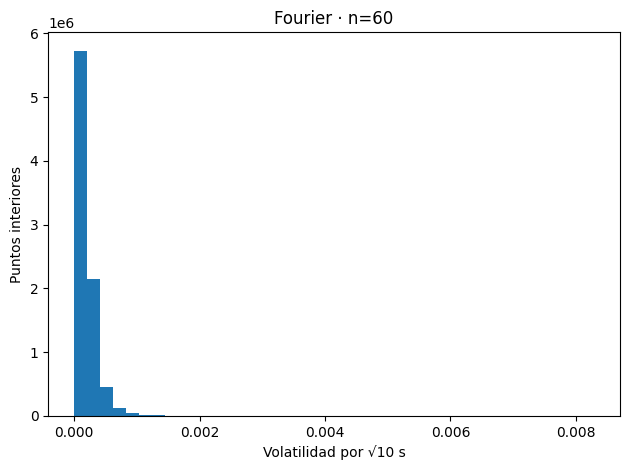

,status,ventanas
0,ruido cero o pilotos inválidos,6
1,ok,144561
2,incompleta,2


,test,statistic,p,status,elegibles,usados,alpha,beta,hac,delta_mse,rezago
0,Mincer-Zarnowitz,335.611207,1.327249e-73,ok,144460,9541,-6.642538e-08,1.132826,11.0,NaN,NaN
1,Diebold-Mariano,0.827266,4.080861e-01,ok,144460,9541,NaN,NaN,11.0,1.463551e-13,NaN
2,Ljung-Box,413.195944,7.386831e-92,ok,144460,9541,NaN,NaN,NaN,NaN,1.0
3,Ljung-Box,432.623393,2.747994e-91,ok,144460,9541,NaN,NaN,NaN,NaN,5.0
4,Ljung-Box,441.569881,1.311864e-88,ok,144460,9541,NaN,NaN,NaN,NaN,10.0


In [ ]:
analyze_fourier(60)

MINCER-ZARNOWITZ
El estadístico de prueba conjunta arroja un valor muy alto (335.61) con un p-valor prácticamente de 0 (1.32 × 10⁻⁷³). Se rechaza categóricamente la hipótesis nula de eficiencia (H₀: α = 0, β = 1).

 Como β > 1, significa que tu estimador de Fourier está subestimando sistemáticamente la magnitud de la volatilidad realizada real. Para corregir el R2, tu modelo necesita "amplificar" la volatilidad de Fourier multiplicándola por 1.13.

DIEBOLD-MARIANO

El p-valor es de 0.408 (mayor a 0.05). No se puede rechazar la hipótesis nula de igualdad en la precisión predictiva/de ajuste.

•  pesar del sesgo de escala encontrado en la regresión MZ, la distancia matemática (evaluada a través del MSE/QLIKE representado por el delta_mse diminuto de 1.46 × 10⁻¹³) demuestra que tu estimador de Fourier es estadísticamente igual de competitivo y robusto que el estimador proxy (R²). Estructuralmente la curva copia bien la dinámica temporal.


LJUNG-BOX (autocorrelacion en los residuos)

•  Para los rezagos 1, 5 y 10, los p-valores son críticamente 0 (7.38 × 10⁻⁹², etc.). Se rechaza fuertemente la hipótesis de ruido blanco en los residuos.
Los residuos estandarizados conservan una altísima autocorrelación serial. Esto es un síntoma inequívoco de que tu spot volatilidad de Fourier está sufriendo de un problema de calibración en sus frecuencias: dejaste patrones sistemáticos de volatilidad o microestructura dentro de los residuos. La curva de volatilidad calculada quedó "demasiado suave" o "desfasada", perdiéndose información cíclica de alta frecuencia que el estimador de Fourier debió haber capturado.

## n = 120 · 20 minutos
Trayectoria spot, histogramas y contrastes de Mincer–Zarnowitz, Diebold–Mariano y Ljung–Box.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

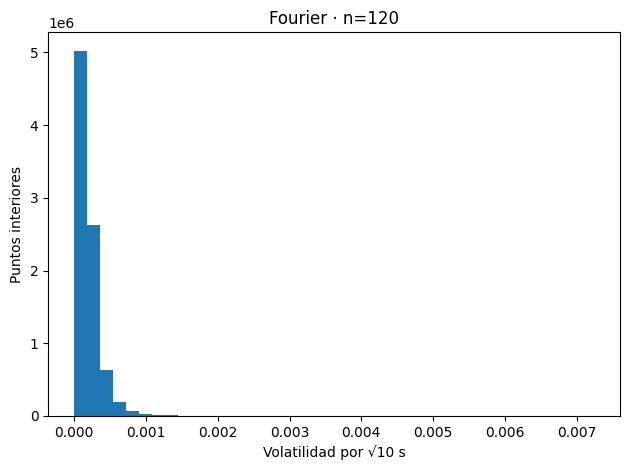

,status,ventanas
0,ruido cero o pilotos inválidos,2
1,incompleta,2
2,ok,72281


,test,statistic,p,status,elegibles,usados,alpha,beta,hac,delta_mse,rezago
0,Mincer-Zarnowitz,376.833121,1.485004e-82,ok,72268,17341,7.320461e-09,0.389023,12.0,NaN,NaN
1,Diebold-Mariano,0.261382,7.937980e-01,ok,72268,17341,NaN,NaN,12.0,2.629511e-15,NaN
2,Ljung-Box,289.675611,5.851106e-65,ok,72268,17341,NaN,NaN,NaN,NaN,1.0
3,Ljung-Box,297.317089,3.779531e-62,ok,72268,17341,NaN,NaN,NaN,NaN,5.0
4,Ljung-Box,303.324790,3.080977e-59,ok,72268,17341,NaN,NaN,NaN,NaN,10.0


In [ ]:
analyze_fourier(120)

## n = 360 · 1 hora
Trayectoria spot, histogramas y contrastes de Mincer–Zarnowitz, Diebold–Mariano y Ljung–Box.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

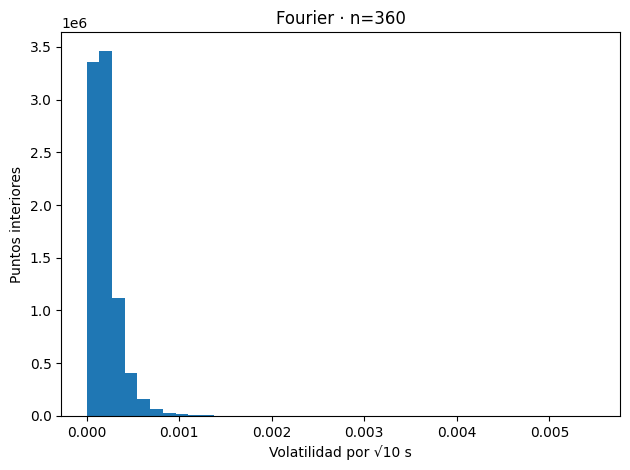

,status,ventanas
0,incompleta,2
1,ok,24093


,test,statistic,p,status,elegibles,usados,alpha,beta,hac,delta_mse,rezago
0,Mincer-Zarnowitz,316.646443,1.742202e-69,ok,24093,24093,2.898046e-09,0.585429,13.0,NaN,NaN
1,Diebold-Mariano,-0.836443,4.029056e-01,ok,24093,24093,NaN,NaN,13.0,-7.142715e-15,NaN
2,Ljung-Box,73.927529,8.103823e-18,ok,24093,24093,NaN,NaN,NaN,NaN,1.0
3,Ljung-Box,226.458024,6.141943e-47,ok,24093,24093,NaN,NaN,NaN,NaN,5.0
4,Ljung-Box,281.945237,1.011830e-54,ok,24093,24093,NaN,NaN,NaN,NaN,10.0


In [ ]:
analyze_fourier(360)

## n = 2160 · 6 horas
Trayectoria spot, histogramas y contrastes de Mincer–Zarnowitz, Diebold–Mariano y Ljung–Box.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

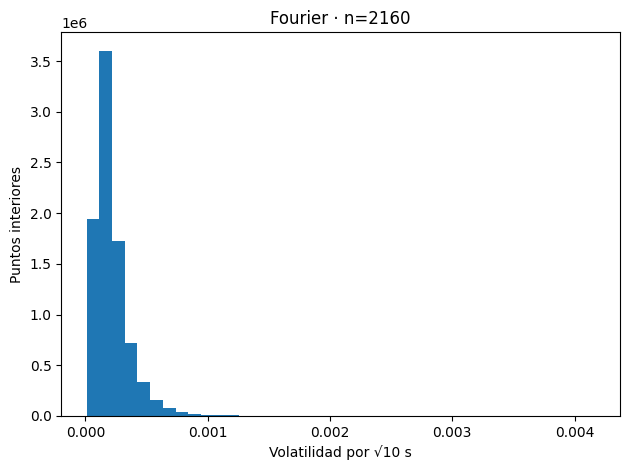

,status,ventanas
0,incompleta,2
1,ok,4014


,test,statistic,p,status,elegibles,usados,alpha,beta,hac,delta_mse,rezago
0,Mincer-Zarnowitz,199.454594,4.886357e-44,ok,4014,4014,1.630424e-08,0.340465,9.0,NaN,NaN
1,Diebold-Mariano,1.733050,8.308677e-02,ok,4014,4014,NaN,NaN,9.0,3.090256e-14,NaN
2,Ljung-Box,2.120439,1.453449e-01,ok,4014,4014,NaN,NaN,NaN,NaN,1.0
3,Ljung-Box,17.008492,4.483720e-03,ok,4014,4014,NaN,NaN,NaN,NaN,5.0
4,Ljung-Box,24.558432,6.248385e-03,ok,4014,4014,NaN,NaN,NaN,NaN,10.0


In [ ]:
analyze_fourier(2160)

## n = 8640 · 1 día
Trayectoria spot, histogramas y contrastes de Mincer–Zarnowitz, Diebold–Mariano y Ljung–Box.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

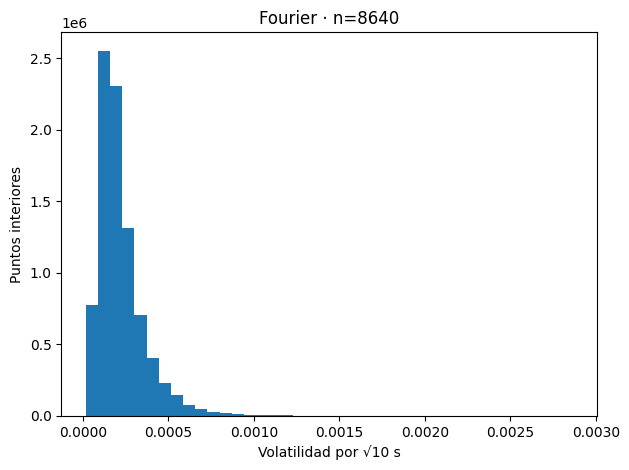

,status,ventanas
0,incompleta,2
1,ok,1002


,test,statistic,p,status,elegibles,usados,alpha,beta,hac,delta_mse,rezago
0,Mincer-Zarnowitz,104.118517,2.460091e-23,ok,1002,1002,-4.334675e-09,0.57008,6.0,NaN,NaN
1,Diebold-Mariano,2.337706,1.940248e-02,ok,1002,1002,NaN,NaN,6.0,5.732106e-15,NaN
2,Ljung-Box,13.733460,2.106678e-04,ok,1002,1002,NaN,NaN,NaN,NaN,1.0
3,Ljung-Box,42.991889,3.709089e-08,ok,1002,1002,NaN,NaN,NaN,NaN,5.0
4,Ljung-Box,59.847804,3.872734e-09,ok,1002,1002,NaN,NaN,NaN,NaN,10.0


In [ ]:
analyze_fourier(8640)

The updated regression analysis reflects a significant reduction to 1,002 observations, showing a Mincer-Zarnowitz slope (\(\beta \)) of 0.5701 and a Diebold-Mariano p-value of 0.0194, which indicates that the Fourier estimator is now overestimating volatility and underperforming relative to the benchmark. Ljung-Box tests continue to show significant residual autocorrelation, likely driven by high-frequency market microstructure noise rather than structural cycles. For more details, consult the relevant statistical methodology documentation.


## n = 60480 · 7 días
Trayectoria spot, histogramas y contrastes de Mincer–Zarnowitz, Diebold–Mariano y Ljung–Box.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

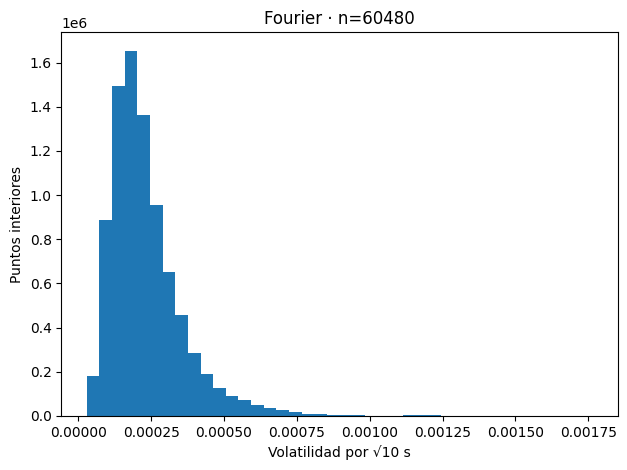

,status,ventanas
0,incompleta,2
1,ok,142


,test,statistic,p,status,elegibles,usados,alpha,beta,hac,delta_mse,rezago
0,Mincer-Zarnowitz,87.772091,8.720322e-20,ok,142,142,3.749951e-09,0.357005,4.0,NaN,NaN
1,Diebold-Mariano,3.939979,8.148882e-05,ok,142,142,NaN,NaN,4.0,3.814725e-15,NaN
2,Ljung-Box,0.020613,8.858378e-01,ok,142,142,NaN,NaN,NaN,NaN,1.0
3,Ljung-Box,6.539233,2.572237e-01,ok,142,142,NaN,NaN,NaN,NaN,5.0
4,Ljung-Box,8.752415,5.557505e-01,ok,142,142,NaN,NaN,NaN,NaN,10.0


In [ ]:
analyze_fourier(60480)

## Tamaño muestral del artículo · referencia adicional
La metodología estricta proporciona $N^*,M^*$ para cada $n$ observado. El $n^*$ óptimo entre duraciones queda **sin identificar**. Esta celda reproduce el conteo de su aplicación empírica (23 400 retornos); trasladado a 10 s cubre **65 horas**. Es una referencia adicional. Para reproducir en BTC el criterio de una jornada de mercado completa, usar la sección de 8640 incrementos. Ambas secciones incluyen sus propios histogramas y contrastes.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

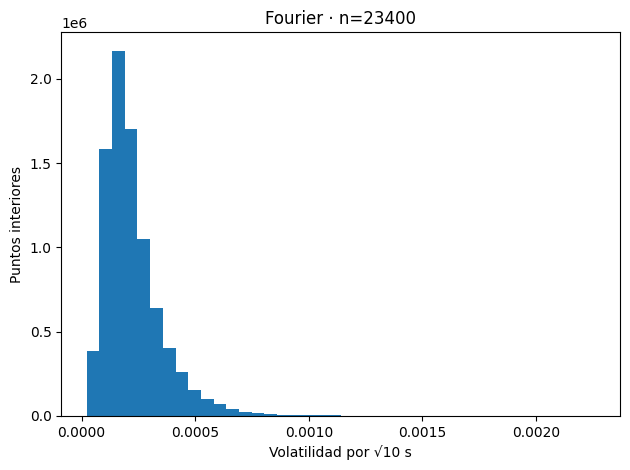

,status,ventanas
0,incompleta,2
1,ok,370


,test,statistic,p,status,elegibles,usados,alpha,beta,hac,delta_mse,rezago
0,Mincer-Zarnowitz,47.831111,4.107771e-11,ok,370,370,2.984082e-08,0.156384,5.0,NaN,NaN
1,Diebold-Mariano,0.920311,3.574103e-01,ok,370,370,NaN,NaN,5.0,2.017029e-14,NaN
2,Ljung-Box,1.413470,2.344812e-01,ok,370,370,NaN,NaN,NaN,NaN,1.0
3,Ljung-Box,3.135565,6.790948e-01,ok,370,370,NaN,NaN,NaN,NaN,5.0
4,Ljung-Box,5.769230,8.342645e-01,ok,370,370,NaN,NaN,NaN,NaN,10.0


In [ ]:
n_articulo = int(6.5 * 3600 / 1)
analyze_fourier(n_articulo)

# Extensión · ventanas cortas y predicción de los últimos minutos
Ejecución manual. En una sesión nueva, correr las celdas originales de acceso y preparación y las dos definiciones Fourier. Si ya existe el Parquet de 10 minutos en la ruta original, la siguiente regresión y el armado de episodios pueden reutilizarlo. Las secciones de 5, 12 y 15 minutos son independientes.

## 10 minutos · Mincer–Zarnowitz sobre todos los pares válidos
Variación exclusiva de muestra: usa la misma regla de pronóstico Fourier, la misma RV del siguiente intervalo de 10 s y la misma hipótesis conjunta (intercepto 0, pendiente 1). Incluye todos los pares finitos, incluso en tramos separados. La covarianza HAC usa pesos Bartlett por desfase de **reloj**: dos observaciones a ambos lados de un hueco sólo contribuyen a su distancia temporal real. Los resultados anteriores por tramo se conservan en su sección. El contraste sigue condicionado a que la estimación sea elegible.

In [ ]:
def mz_all_10min():
    """Wald HAC con pesos Bartlett a distancias reales de 600 s."""
    folder = FOURIER_OUT/'n_60'
    source = qstr(str(folder/'ventanas.parquet'))
    data = con.execute(f"""SELECT "end", target, forecast FROM read_parquet({source})
        WHERE status IN ('ok','limite_K') AND isfinite(forecast) AND forecast>=0
          AND isfinite(target) ORDER BY "end" """).df()
    def save(**values):
        result = pd.DataFrame([dict(test='Mincer-Zarnowitz', usados=len(data), **values)])
        result.to_csv(folder/'mz_todos.csv', index=False)
        display(result)
    if len(data)<MIN_TEST or data.forecast.nunique()<2:
        return save(status='muestra insuficiente o pronóstico constante')
    scale = max(data.target.mean(),data.forecast.mean(),np.finfo(float).tiny)
    X = np.column_stack((np.ones(len(data)),data.forecast.to_numpy()/scale))
    y = data.target.to_numpy()/scale
    beta, _, rank, _ = np.linalg.lstsq(X, y, rcond=None)
    if rank<2:
        return save(status='regresión singular')
    times = data['end'].to_numpy()
    if np.any(np.diff(times)<=0):
        raise ValueError('Cierres duplicados o fuera de orden.')
    score = X*(y-X@beta)[:,None]
    meat = score.T@score
    lag = max(1,int(4*(len(y)/100)**(2/9)))
    for j in range(1,lag+1):
        earlier = times-600*j
        idx = np.searchsorted(times,earlier)
        hits = times[idx]==earlier
        cross = score[hits].T@score[idx[hits]]
        meat += (1-j/(lag+1))*(cross+cross.T)
    bread = np.linalg.inv(X.T@X)
    cov = bread@meat@bread
    if np.linalg.matrix_rank(cov)<2:
        return save(status='covarianza singular')
    delta = beta-np.array([0.,1.])
    w = float(delta@np.linalg.solve(cov,delta))
    se = np.sqrt(np.diag(cov))
    save(status='ok', statistic=w, p=stats.chi2.sf(w,2), alpha=beta[0]*scale,
         beta=beta[1], beta_ic95_inf=beta[1]-1.96*se[1], beta_ic95_sup=beta[1]+1.96*se[1],
         hac_bloques=lag, desde_utc=pd.to_datetime(times[0],unit='s',utc=True),
         hasta_utc=pd.to_datetime(times[-1],unit='s',utc=True))
mz_all_10min()

,test,usados,status,statistic,p,alpha,beta,beta_ic95_inf,beta_ic95_sup,hac_bloques,desde_utc,hasta_utc
0,Mincer-Zarnowitz,144460,ok,731.223991,1.647130e-159,4.398687e-09,0.590111,0.38899,0.791232,20,2023-01-01 00:19:59+00:00,2025-09-30 22:39:59+00:00


## 5 minutos · n = 30
Misma reconstrucción Fourier, selección adaptativa por bloque, histogramas y tres contrastes sobre la regla de pronóstico a 10 s. La sección anterior amplía únicamente Mincer–Zarnowitz de 10 minutos.

In [ ]:
analyze_fourier(30)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 12 minutos · n = 72
Misma reconstrucción Fourier, selección adaptativa por bloque, histogramas y tres contrastes sobre la regla de pronóstico a 10 s. La sección anterior amplía únicamente Mincer–Zarnowitz de 10 minutos.

In [ ]:
analyze_fourier(72)

## 15 minutos · n = 90
Misma reconstrucción Fourier, selección adaptativa por bloque, histogramas y tres contrastes sobre la regla de pronóstico a 10 s. La sección anterior amplía únicamente Mincer–Zarnowitz de 10 minutos.

In [ ]:
analyze_fourier(90)

## LSTM · corte interno y dos trayectorias de volatilidad
Un episodio de $n$ retornos se divide en un prefijo de $n-h$ y una cola de $h=12$ o $18$ pasos. En 10 minutos corresponden a 48→12 y 42→18. Se pronostican todos los pasos de la cola directamente. Cada paso de salida corresponde al centro de una barra futura de 10 s; el último representa la barra que termina a 2 o 3 minutos del corte.

Las **entradas** son retornos en puntos básicos, amplitud absoluta, coeficientes complejos de Fourier (primera frecuencia en 8, 16 y 32 pasos) y detalles Haar en 2, 4 y 8 pasos. Se calculan hacia atrás en cada paso dentro del prefijo; las escalas aún indisponibles llevan indicador explícito. Los períodos Fourier representan hasta 320 s; la tendencia diaria exigiría historia adicional. Para los dos horizontes se almacena una sola secuencia truncada al mayor prefijo; el lector acorta físicamente la entrada para el horizonte más largo.

Las **etiquetas** son dos aproximaciones a la volatilidad local, ambas en puntos básicos por intervalo de 10 s. Fourier reconstruye la curva retrospectiva del episodio completo con sus $N,M$ guardados, evaluada en los centros de las barras para evitar los extremos periódicos. Haar usa la raíz de la media de siete detalles finos al cuadrado, calculados sobre ocho retornos hasta la barra etiquetada. Es una proxy suavizada y rezagada, sensible al ruido microestructural. Ambas etiquetas comparten observaciones con el prefijo por construcción. Se informa por separado el error frente a la raíz de la RV observada exclusivamente en cada barra futura y frente a persistencia de la RV disponible al corte.

Las ventanas calendarias son disjuntas. Partición cronológica 70/15/15 por tiempo, excluyendo bloques que crucen fronteras. Las salidas Fourier negativas se enmascaran sólo en esa etiqueta. Dos modelos independientes evitan mezclar prefijos. La LSTM tiene 32 unidades internas; la duración del episodio la fijan sus pasos temporales. El entrenamiento lee Parquet en lotes y sólo mezcla ejemplos de entrenamiento con un búfer acotado.

In [ ]:
# Un registro por bloque. Las dos duraciones comparten el mismo Parquet.
from numpy.lib.stride_tricks import sliding_window_view
HORIZONS = (12,18)   # pasos de 10 s
FEATURES = ('ret_bp','abs_ret_bp','fourier_re_k1','fourier_im_k1','fourier_disponible',
            'haar_2','haar_4','haar_8','disp_2','disp_4','disp_8',
            'fourier_re_16','fourier_im_16','disp_F16',
            'fourier_re_32','fourier_im_32','disp_F32')
def causal_features(r):
    x = r*10000.0
    a = np.zeros((len(r),len(FEATURES)),dtype=np.float32)
    a[:,0], a[:,1] = x, np.abs(x)
    # Primera frecuencia en tres escalas locales; fase referida al cierre.
    for width,col in ((8,2),(16,11),(32,14)):
        if len(x)>=width:
            windows = sliding_window_view(x,width)
            phase = np.exp(-2j*np.pi*np.arange(1-width,1)/width)
            z = windows@phase/np.sqrt(width)
            a[width-1:,col:col+3] = np.column_stack((z.real,z.imag,np.ones(len(z))))
    for j,w in enumerate((2,4,8)):
        history = sliding_window_view(x,w)
        d = (history[:,w//2:].sum(axis=1)-history[:,:w//2].sum(axis=1))/np.sqrt(w)
        a[w-1:,5+j], a[w-1:,8+j] = d, 1
    return a

def spot_labels(r,N,M):
    # Rejilla interior en los centros de las barras, incluido el de la última.
    n = len(r)
    k = np.arange(M+1)
    coef = variance_coefficients(np.fft.fft(r),N,M)
    spectrum = np.zeros(n//2+1,dtype=complex)
    spectrum[:M+1] = coef*(1-k/(M+1))*np.exp(1j*np.pi*k/n)
    var_f = np.fft.irfft(spectrum,n=n)
    # Proxy local Haar: para incrementos incorrelados de varianza local v,
    # E[(r_j-r_{j-1})²/2] ≈ v. Promediar 7 detalles sobre 8 retornos.
    detail_power = np.diff(r)**2/2
    var_w = np.full(n,np.nan)
    var_w[7:] = sliding_window_view(detail_power,7).mean(axis=1)
    return 10000*np.sqrt(np.column_stack((np.where(var_f>=0,var_f,np.nan),var_w)))

def sample_file(n):
    return FOURIER_OUT/f'n_{n}'/'lstm_2_3min.parquet'

def build_samples(n=60):
    if n<=max(HORIZONS)+7:
        raise ValueError('Prefijo demasiado corto para las escalas de entrada.')
    destination = sample_file(n)
    meta = qstr(str(destination.parent/'ventanas.parquet'))
    cuts = con.execute(f"""SELECT "end",N,M FROM read_parquet({meta})
        WHERE status IN ('ok','limite_K') AND n={int(n)}""").df().set_index('end')
    schema = pa.schema([('end',pa.int64()),('features',pa.list_(pa.float32())),
                         ('labels_bp',pa.list_(pa.float32())),('rv_sigma_bp',pa.list_(pa.float32()))])
    temp = destination.with_suffix('.partial')
    rows = []
    with pq.ParquetWriter(temp,schema,compression='zstd') as writer:
        for block in blocks(n):
            end = int(block.sec.iloc[-1])
            if end not in cuts.index or len(block)!=n:
                continue
            r = block.r.to_numpy(dtype=float)
            if not np.isfinite(r).all() or not np.all(np.diff(block.sec)==10):
                continue
            N,M = cuts.loc[end,['N','M']].astype(int)
            labels = spot_labels(r,N,M)[-max(HORIZONS):]
            rv = block.rv.to_numpy(dtype=float)
            # El último retorno del prefijo más largo termina antes de ambas salidas respectivas.
            rows.append(dict(end=end,features=causal_features(r[:-min(HORIZONS)]).ravel(),
                             labels_bp=labels.astype('float32').ravel(),
                             rv_sigma_bp=(10000*np.sqrt(rv[-(max(HORIZONS)+1):])).astype('float32')))
            if len(rows)==512:
                writer.write_table(pa.Table.from_pylist(rows,schema=schema))
                rows.clear()
        if rows:
            writer.write_table(pa.Table.from_pylist(rows,schema=schema))
    temp.replace(destination)
    print(destination, 'bloques:', pq.read_metadata(destination).num_rows)

In [ ]:
# Dependencias de entrenamiento sólo al llamar a train_tail().
def train_tail(n=60,h=12,epochs=15,batch_size=64):
    import tensorflow as tf
    import pyarrow.dataset as ds
    if h not in HORIZONS:
        raise ValueError('h debe ser 12 o 18 pasos.')
    tf.keras.utils.set_random_seed(42)
    dataset = ds.dataset(str(sample_file(n)),format='parquet')
    if not dataset.count_rows():
        raise ValueError('No hay bloques elegibles.')
    q = qstr(str(sample_file(n)))
    first,last = con.execute(f'SELECT min("end"),max("end") FROM read_parquet({q})').fetchone()
    # Fronteras por reloj, compartidas por ambos horizontes para el mismo n.
    train_end = int(first+0.70*(last-first))
    valid_end = int(first+0.85*(last-first))
    end = ds.field('end')
    filters = {'train':end<train_end,
               'valid':(end>=train_end+n*10)&(end<valid_end),
               'test':end>=valid_end+n*10}
    for name,flt in filters.items():
        if not dataset.count_rows(filter=flt):
            raise ValueError(f'Sin episodios para {name}.')
    def records(split):
        scanner = dataset.scanner(filter=filters[split],batch_size=128,
                                  batch_readahead=1,fragment_readahead=1,use_threads=False)
        for batch in scanner.to_batches():
            for row in batch.to_pylist():
                x = np.asarray(row['features'],'float32').reshape(n-min(HORIZONS),len(FEATURES))[:n-h]
                y = np.asarray(row['labels_bp'],'float32').reshape(max(HORIZONS),2)[-h:]
                mask = np.isfinite(y)
                rv = np.asarray(row['rv_sigma_bp'],'float32')
                yield row['end'], x, np.where(mask,y,0), mask.astype('float32'), rv
    def stream(split):
        def triples():
            for _,x,y,w,_ in records(split):
                yield x,y,w
        shapes = ((n-h,len(FEATURES)),(h,2),(h,2))
        tfdata = tf.data.Dataset.from_generator(triples,output_signature=tuple(
            tf.TensorSpec(shape,tf.float32) for shape in shapes))
        if split=='train':
            tfdata = tfdata.shuffle(512,seed=42)
        return tfdata.batch(batch_size).prefetch(1)
    train,valid = stream('train'),stream('valid')
    @tf.keras.utils.register_keras_serializable(package='BTC')
    def squared_by_target(y_true,y_pred):
        return tf.math.squared_difference(y_true,y_pred)
    inputs = tf.keras.Input(shape=(n-h,len(FEATURES)))
    state = tf.keras.layers.LSTM(32)(inputs)
    pred = tf.keras.layers.Dense(h*2,activation='softplus')(state)
    model = tf.keras.Model(inputs,tf.keras.layers.Reshape((h,2))(pred))
    model.compile(optimizer='adam',loss=squared_by_target)
    history = model.fit(train,validation_data=valid,epochs=epochs,verbose=2,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)])
    folder = sample_file(n).parent/f'lstm_h{h}'
    folder.mkdir(exist_ok=True)
    model.save(folder/'modelo.keras')
    pd.DataFrame(history.history).to_csv(folder/'entrenamiento.csv',index=False)
    # Predicciones y proxy externa (siguiente RV por barra): flujo acotado a un lote.
    schema = pa.schema([('end',pa.int64()),('step',pa.int32()),
        ('fourier_bp',pa.float32()),('haar_bp',pa.float32()),
        ('pred_fourier_bp',pa.float32()),('pred_haar_bp',pa.float32()),
        ('rv_bp',pa.float32()),('persistencia_rv_bp',pa.float32())])
    def write_batch(writer,items):
        preds = model(np.stack([v[1] for v in items]),training=False).numpy()
        rows = []
        for (timestamp,_,y,w,rv),p in zip(items,preds):
            for j in range(h):
                rows.append(dict(end=timestamp,step=j+1,
                    fourier_bp=float(y[j,0]) if w[j,0] else None,haar_bp=float(y[j,1]),
                    pred_fourier_bp=float(p[j,0]),pred_haar_bp=float(p[j,1]),
                    rv_bp=float(rv[-h+j]),persistencia_rv_bp=float(rv[-h-1])))
        writer.write_table(pa.Table.from_pylist(rows,schema=schema))
    path = folder/'test.parquet'
    temp = path.with_suffix('.partial')
    with pq.ParquetWriter(temp,schema,compression='zstd') as writer:
        items = []
        for sample in records('test'):
            items.append(sample)
            if len(items)==batch_size:
                write_batch(writer,items)
                items.clear()
        if items:
            write_batch(writer,items)
    temp.replace(path)
    scores = con.execute(f"""SELECT step, count(*) AS bloques,
        sqrt(avg((pred_fourier_bp-fourier_bp)^2)) AS rmse_fourier_bp,
        sqrt(avg((pred_haar_bp-haar_bp)^2)) AS rmse_haar_bp,
        sqrt(avg((pred_fourier_bp-rv_bp)^2)) AS rmse_F_vs_RV,
        sqrt(avg((pred_haar_bp-rv_bp)^2)) AS rmse_H_vs_RV,
        sqrt(avg((persistencia_rv_bp-rv_bp)^2)) AS rmse_persistencia_vs_RV
        FROM read_parquet({qstr(str(path))}) GROUP BY step ORDER BY step""").df()
    scores.to_csv(folder/'metricas_test.csv',index=False)
    display(scores)
    tf.keras.backend.clear_session()

### Preparar episodios de 10 minutos
La celda reutiliza los $N,M$ del archivo `n_60/ventanas.parquet`. Si falta, ejecutar antes la sección Fourier de 10 minutos. Para otra longitud, correr su sección Fourier y cambiar `N_LSTM` aquí; 30, 60, 72 y 90 pasos cubren los cuatro diseños cortos.

In [ ]:
N_LSTM = 60
build_samples(N_LSTM)

### Cola de 2 minutos · entrenamiento y evaluación por paso

In [ ]:
train_tail(n=N_LSTM,h=12)

### Cola de 3 minutos · entrenamiento y evaluación por paso

In [ ]:
train_tail(n=N_LSTM,h=18)